# ЛР-3. Разработка аналитического дашборда для бизнес-кейса
**Дисциплина:** Программные средства сбора, консолидации и аналитики данных · **Направление:** 38.04.05 «Бизнес-информатика», магистратура

**Цель работы.** Освоить полный цикл аналитики данных для прикладной бизнес-задачи: собрать открытые данные из нескольких
источников, консолидировать их в аналитическом хранилище (SQLite), спроектировать SQL-витрину под свой бизнес-кейс
и построить интерактивный дашборд в Yandex DataLens. Научиться формулировать бизнес-выводы по дашборду.

**Результат:** витрина `dm_vNN_…` в SQLite → CSV → дашборд DataLens из 5 типов чартов с селекторами → отчёт `README.md` в Git.

**Как работать:** выполняйте ячейки сверху вниз (`Shift + Enter`). Ячейки с пометкой **✏️ ЗАДАНИЕ** заполняете вы,
после них идёт **автотест** — он подтверждает, что задание выполнено верно. Остальной код читайте и разбирайте: он и есть конвейер.
Время: ≈ 1 ч на разделы 1–6 и ≈ 1,5 ч на DataLens и отчёт.

## 0. Что изменилось и как устроен конвейер

Раньше работа выполнялась в виртуальной машине: **Kaggle API → Apache Airflow → PostgreSQL → Apache Superset** в Docker Compose.
Теперь тот же полный цикл аналитики выполняется **без виртуальной машины и Docker**: в Google Colab или локальном Jupyter.

| Этап | Было (ВМ + Docker) | Стало (Python + SQLite + DataLens) |
|---|---|---|
| Сбор (Extract) | `kagglehub` + токен `kaggle.json` | `urllib` — публичная ссылка Kaggle, токен не нужен |
| Оркестрация | DAG Apache Airflow (4 задачи) | разделы ноутбука 2 → 3 → 4 → 5 (тот же порядок задач) |
| Хранилище | PostgreSQL 12 в контейнере | файл **SQLite** `olist_dwh.sqlite` (встроен в Python) |
| Администрирование БД | pgAdmin 4 | SQL-ячейки ноутбука (по желанию — DB Browser for SQLite) |
| Витрина данных | `CREATE VIEW` в PostgreSQL | `CREATE VIEW` в SQLite → выгрузка **CSV** |
| Визуализация | Apache Superset 3.1 | **Yandex DataLens** (облако, подключение «Файлы») |

**Соответствие задач DAG разделам ноутбука:** `extract_from_kaggle` → раздел 2, `load_raw_to_postgres` → раздел 3,
`transform_and_clean_data` → раздел 4, `create_datamart` → раздел 5. Раздел 6 (выгрузка CSV) и раздел 7 (DataLens) заменяют Superset.

```
 ИСТОЧНИК                 ХРАНИЛИЩЕ SQLite (olist_dwh.sqlite)                         ВИЗУАЛИЗАЦИЯ
┌────────────┐   ┌──────────┐   ┌────────────┐   ┌────────────┐   ┌──────────────┐   ┌──────────────────┐
│ Kaggle     │──▶│ RAW      │──▶│ STAGING    │──▶│ CORE       │──▶│ DATAMART     │──▶│ CSV → DataLens   │
│ Olist, ZIP │   │ 9 таблиц │   │ типы,      │   │ core_order │   │ dm_vNN_…     │   │ подключение →    │
│ 9 CSV      │   │ как есть │   │ очистка,   │   │ core_item  │   │ (VIEW вашего │   │ датасет → чарты →│
│ 44,7 МБ    │   │ (TEXT)   │   │ дедупликац.│   │ + dim_state│   │  варианта)   │   │ дашборд          │
└────────────┘   └──────────┘   └────────────┘   └────────────┘   └──────────────┘   └──────────────────┘
   EXTRACT           LOAD             TRANSFORM (SQL)                MART (SQL)          LOAD → BI
```

### Датасет: Brazilian E-Commerce Public Dataset by Olist
Реальные обезличенные данные бразильского маркетплейса Olist: **≈ 99 тыс. заказов за 2016–2018 гг.**, 9 связанных таблиц,
≈ 1,55 млн строк, архив **44,7 МБ** (лицензия CC BY-NC-SA 4.0, учебное использование разрешено).
Датасет закрывает основные предметные области бизнес-информатики: продажи, клиенты и маркетинг, платежи, логистика,
работа с поставщиками (продавцами), качество сервиса, товарный ассортимент.

| Таблица | Строк | Что описывает |
|---|---:|---|
| `olist_orders_dataset` | 99 441 | заказ: статус и 5 временных меток жизненного цикла |
| `olist_order_items_dataset` | 112 650 | позиции заказа: товар, продавец, цена, стоимость доставки |
| `olist_order_payments_dataset` | 103 886 | платежи: способ оплаты, число взносов, сумма |
| `olist_order_reviews_dataset` | 99 224 | отзывы: оценка 1–5, комментарий, даты |
| `olist_customers_dataset` | 99 441 | клиенты: уникальный ID, город, штат |
| `olist_sellers_dataset` | 3 095 | продавцы: город, штат |
| `olist_products_dataset` | 32 951 | товары: категория, фото, описание, вес и габариты |
| `product_category_name_translation` | 71 | перевод категорий с португальского |
| `olist_geolocation_dataset` | 1 000 163 | координаты почтовых индексов |

### Критерии оценивания (20 баллов)

| № | Критерий | Баллы |
|---|---|:---:|
| 1 | Конвейер RAW → STAGING → CORE построен в SQLite, все автотесты раздела 4 пройдены | 4 |
| 2 | SQL-витрина варианта: верные гранулярность и столбцы, автотест раздела 5 пройден | 4 |
| 3 | Контрольные значения варианта рассчитаны, корректны и сопоставлены с контрольными ориентирами (допуск ± 0,1 при сопоставимой методике) | 3 |
| 4 | Дашборд DataLens: 5 обязательных типов диаграмм, правильно настроенные вычисляемые поля датасета | 5 |
| 5 | Интерактивность: не менее 2 селекторов, связанных с диаграммами; заголовки и подписи | 1 |
| 6 | Отчёт `README.md` в Git: структура, скриншоты, ссылка на дашборд, не менее 3 аргументированных бизнес-выводов с числами и рекомендация | 3 |
|   | **Итого** | **20** |

**Сдача:** ссылка на публичный Git-репозиторий (ноутбук, SQL витрины, CSV-словарь полей, `README.md` со скриншотами) и ссылка на дашборд DataLens. Архивы и отдельные файлы вместо ссылок не принимаются.


## 1. Параметры работы и вариант

In [1]:
#@title ✏️ 1.1. Укажите номер варианта, ФИО и группу
VARIANT = 30              #@param {type:"integer"}
STUDENT = "Трусов А.И." #@param {type:"string"}
GROUP   = "БД-251м"       #@param {type:"string"}
assert 1 <= VARIANT <= 30, "Номер варианта должен быть от 1 до 30 (выдаёт преподаватель)"
print(f"Вариант {VARIANT}: {STUDENT}, {GROUP}")

Вариант 30: Трусов А.И., БД-251м


In [2]:
# === 1.1. Импорт библиотек и параметры работы ===
import os, io, sys, json, time, zipfile, hashlib, sqlite3, urllib.request
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

WORK_DIR = Path("lab3_olist")                    # рабочая папка проекта
RAW_DIR  = WORK_DIR / "data" / "raw"             # исходные CSV (как скачали)
OUT_DIR  = WORK_DIR / "data" / "datalens"        # CSV-выгрузки для DataLens
DB_PATH  = WORK_DIR / "olist_dwh.sqlite"         # локальное хранилище (SQLite)
for d in (RAW_DIR, OUT_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("Python", sys.version.split()[0], "| SQLite", sqlite3.sqlite_version, "| pandas", pd.__version__)
print("Рабочая папка:", WORK_DIR.resolve())

Python 3.13.18 | SQLite 3.45.1 | pandas 2.2.3
Рабочая папка: /content/lab3_olist


In [3]:
#@title Справочник 30 вариантов (запустите ячейку, не изменяйте)
VARIANTS = [{'v': 1,
  'domain': 'Продажи',
  'slug': 'sales_monthly',
  'dm': 'dm_v01_sales_monthly',
  'title': 'Динамика выручки и заказов',
  'question': 'Как меняются выручка (GMV), число заказов и средний чек по месяцам и макрорегионам? Есть ли '
              'устойчивый рост?',
  'grain': 'месяц × штат',
  'key': ['month', 'state'],
  'columns': ['month', 'year', 'region', 'state', 'orders', 'gmv', 'items', 'customers'],
  'calc': {'Средний чек': 'SUM([gmv]) / SUM([orders])'},
  'charts': [('Индикатор', 'Выручка за период', 'Показатель: SUM(gmv)'),
             ('Линейная диаграмма', 'Выручка по месяцам', 'X: month (Дата, группировка «Месяц»); Y: SUM(gmv)'),
             ('Столбчатая диаграмма',
              'Заказы по регионам',
              'X: region; Y: SUM(orders); Сортировка: SUM(orders) по убыванию'),
             ('Круговая диаграмма',
              'Доля регионов в выручке',
              'Цвета: region; Показатели: SUM(gmv); Подписи: в процентах'),
             ('Комбинированная диаграмма',
              'Заказы и средний чек',
              'X: month; Слой 1 (столбчатая) Y: SUM(orders); Слой 2 (линейная) Y: «Средний чек»')],
  'extra': None,
  'selectors': ['region', 'year'],
  'controls': [('Месяц с максимальной выручкой (YYYY-MM-01)',
                'SELECT month FROM {dm} GROUP BY month ORDER BY SUM(gmv) DESC LIMIT 1'),
               ('Рост GMV за янв–авг 2018 к янв–авг 2017, %',
                'SELECT ROUND(100.0*(SUM(CASE WHEN year=2018 THEN gmv END)/SUM(CASE WHEN year=2017 AND '
                "month<'2017-09-01' THEN gmv END)-1),1) FROM {dm}")]},
 {'v': 2,
  'domain': 'Продажи',
  'slug': 'category_sales',
  'dm': 'dm_v02_category_sales',
  'title': 'Выручка по товарным категориям',
  'question': 'Какие категории формируют выручку, как меняется их вклад во времени и какова средняя цена товара в '
              'категории?',
  'grain': 'месяц × категория',
  'key': ['month', 'category'],
  'columns': ['month', 'category', 'items', 'orders', 'revenue', 'freight'],
  'calc': {'Средняя цена': 'SUM([revenue]) / SUM([items])'},
  'charts': [('Индикатор', 'Выручка товаров', 'Показатель: SUM(revenue)'),
             ('Линейная диаграмма', 'Выручка по месяцам', 'X: month; Y: SUM(revenue)'),
             ('Линейчатая диаграмма',
              'ТОП-10 категорий',
              'Y: category; X: SUM(revenue); Сортировка по убыванию; фильтр ТОП-10 (Фильтры → category → «Топ»)'),
             ('Круговая диаграмма', 'Структура выручки', 'Цвета: category; Показатели: SUM(revenue)'),
             ('Комбинированная диаграмма',
              'Объём и средняя цена',
              'X: month; Слой 1 (столбчатая): SUM(items); Слой 2 (линейная): «Средняя цена»')],
  'extra': None,
  'selectors': ['category', 'month'],
  'controls': [('Категория № 1 по выручке',
                'SELECT category FROM {dm} GROUP BY category ORDER BY SUM(revenue) DESC LIMIT 1'),
               ('Доля категории № 1 в выручке, %',
                'SELECT ROUND(100.0*MAX(s)/SUM(s),1) FROM (SELECT SUM(revenue) s FROM {dm} GROUP BY category)')]},
 {'v': 3,
  'domain': 'Продажи',
  'slug': 'abc_categories',
  'dm': 'dm_v03_abc_categories',
  'title': 'ABC-анализ товарных категорий',
  'question': 'Какие категории приносят 80 % выручки (класс A), какие — следующие 15 % (B) и какие можно не '
              'развивать (C)?',
  'grain': 'категория',
  'key': ['category'],
  'columns': ['category', 'revenue', 'items', 'rank_num', 'share_pct', 'cum_share_pct', 'abc_class'],
  'calc': {'Число категорий': 'COUNTD([category])'},
  'charts': [('Индикатор', 'Категорий в классе A', 'Показатель: «Число категорий»; Фильтры: abc_class = A'),
             ('Столбчатая диаграмма',
              'Выручка категорий (Парето)',
              'X: category; Y: SUM(revenue); Цвета: abc_class; Сортировка: revenue ↓'),
             ('Круговая диаграмма', 'Выручка по классам ABC', 'Цвета: abc_class; Показатели: SUM(revenue)'),
             ('Линейная диаграмма', 'Кумулятивная доля', 'X: rank_num; Y: MAX(cum_share_pct)'),
             ('Комбинированная диаграмма',
              'Диаграмма Парето',
              'X: category (сортировка по rank_num); Слой 1 столбцы: SUM(share_pct); Слой 2 линия: '
              'MAX(cum_share_pct)')],
  'extra': None,
  'selectors': ['abc_class'],
  'controls': [('Число категорий класса A', "SELECT COUNT(*) FROM {dm} WHERE abc_class='A'"),
               ('Доля выручки класса A, %', "SELECT ROUND(SUM(share_pct),1) FROM {dm} WHERE abc_class='A'")]},
 {'v': 4,
  'domain': 'Продажи',
  'slug': 'purchase_time',
  'dm': 'dm_v04_purchase_time',
  'title': 'Сезонность покупок: день недели и час',
  'question': 'В какие дни и часы покупатели оформляют заказы? Когда запускать рассылки и усиливать поддержку?',
  'grain': 'месяц × день недели × час',
  'key': ['month', 'weekday', 'hour'],
  'columns': ['month', 'weekday', 'hour', 'daypart', 'orders', 'gmv'],
  'calc': {'Средний чек': 'SUM([gmv]) / SUM([orders])'},
  'charts': [('Индикатор', 'Всего заказов', 'Показатель: SUM(orders)'),
             ('Линейная диаграмма', 'Заказы по часам суток', 'X: hour; Y: SUM(orders)'),
             ('Столбчатая диаграмма', 'Заказы по дням недели', 'X: weekday; Y: SUM(orders)'),
             ('Круговая диаграмма', 'Доля частей суток', 'Цвета: daypart; Показатели: SUM(orders)'),
             ('Комбинированная диаграмма',
              'Заказы и чек по часам',
              'X: hour; Слой 1 столбцы: SUM(orders); Слой 2 линия: «Средний чек»')],
  'extra': ('Сводная таблица',
            'Тепловая карта день × час',
            'Строки: weekday; Столбцы: hour; Показатели: SUM(orders); цвет заливки по показателю'),
  'selectors': ['weekday', 'month'],
  'controls': [('Пиковый час покупок', 'SELECT hour FROM {dm} GROUP BY hour ORDER BY SUM(orders) DESC LIMIT 1'),
               ('День недели с максимумом заказов',
                'SELECT weekday FROM {dm} GROUP BY weekday ORDER BY SUM(orders) DESC LIMIT 1')]},
 {'v': 5,
  'domain': 'Продажи',
  'slug': 'basket',
  'dm': 'dm_v05_basket',
  'title': 'Корзина заказа: размер и состав',
  'question': 'Сколько товаров и продавцов в одном заказе? Как размер корзины связан со средним чеком и долей '
              'доставки?',
  'grain': 'заказ',
  'key': ['order_id'],
  'columns': ['order_id',
              'month',
              'region',
              'items_cnt',
              'basket_size',
              'sellers_cnt',
              'multi_seller',
              'goods_value',
              'freight_value',
              'order_value'],
  'calc': {'Средний чек': 'AVG([order_value])',
           'Товаров в заказе': 'SUM([items_cnt]) / COUNT([order_id])',
           'Доля доставки': 'SUM([freight_value]) / SUM([order_value])'},
  'charts': [('Индикатор', 'Товаров в заказе', 'Показатель: «Товаров в заказе»'),
             ('Столбчатая диаграмма', 'Средний чек по размеру корзины', 'X: basket_size; Y: «Средний чек»'),
             ('Круговая диаграмма',
              'Структура заказов по размеру корзины',
              'Цвета: basket_size; Показатели: COUNT(order_id)'),
             ('Линейная диаграмма', 'Товаров в заказе по месяцам', 'X: month; Y: «Товаров в заказе»'),
             ('Комбинированная диаграмма',
              'Заказы и доля доставки',
              'X: basket_size; Слой 1 столбцы: COUNT(order_id); Слой 2 линия: «Доля доставки»')],
  'extra': None,
  'selectors': ['region', 'multi_seller'],
  'controls': [('Доля заказов с 2+ товарами, %', 'SELECT ROUND(100.0*AVG(items_cnt>1),1) FROM {dm}'),
               ('Средний чек заказов «3+ товара», BRL',
                "SELECT ROUND(AVG(order_value),2) FROM {dm} WHERE basket_size='3+ товара'")]},
 {'v': 6,
  'domain': 'Клиенты',
  'slug': 'cohorts',
  'dm': 'dm_v06_cohorts',
  'title': 'Когортный анализ повторных покупок',
  'question': 'Какая доля клиентов каждой когорты (месяц первой покупки) возвращается в следующие месяцы?',
  'grain': 'когорта × смещение',
  'key': ['cohort_month', 'month_offset'],
  'columns': ['cohort_month', 'month_offset', 'active_customers', 'cohort_size', 'retention_pct', 'purchase_type'],
  'calc': {'Удержание, %': 'SUM([active_customers]) / SUM([cohort_size]) * 100'},
  'charts': [('Индикатор', 'Клиентов в когортах', 'Показатель: SUM(active_customers); Фильтры: month_offset = 0'),
             ('Сводная таблица',
              'Матрица удержания',
              'Строки: cohort_month; Столбцы: month_offset; Показатели: MAX(retention_pct); Фильтры: month_offset '
              '1–12'),
             ('Линейная диаграмма',
              'Кривая удержания',
              'X: month_offset; Y: «Удержание, %»; Фильтры: month_offset ≥ 1'),
             ('Столбчатая диаграмма',
              'Размер когорт',
              'X: cohort_month; Y: SUM(active_customers); Фильтры: month_offset = 0'),
             ('Кольцевая диаграмма',
              'Первые и повторные клиент-месяцы',
              'Цвета: purchase_type; Показатели: SUM(active_customers)')],
  'extra': None,
  'selectors': ['cohort_month'],
  'controls': [('Среднее удержание через 1 месяц, %',
                'SELECT ROUND(100.0*SUM(active_customers)/SUM(cohort_size),2) FROM {dm} WHERE month_offset=1'),
               ('Когорта с наибольшим числом клиентов',
                'SELECT cohort_month FROM {dm} WHERE month_offset=0 ORDER BY cohort_size DESC LIMIT 1')]},
 {'v': 7,
  'domain': 'Клиенты',
  'slug': 'rfm',
  'dm': 'dm_v07_rfm',
  'title': 'RFM-сегментация клиентов',
  'question': 'Как распределены клиенты по давности, частоте и сумме покупок? Кого удерживать, кого реактивировать?',
  'grain': 'клиент',
  'key': ['customer_unique_id'],
  'columns': ['customer_unique_id',
              'region',
              'last_purchase',
              'recency_days',
              'frequency',
              'monetary',
              'r_score',
              'm_score',
              'segment'],
  'calc': {'Клиентов': 'COUNTD([customer_unique_id])', 'Средняя сумма': 'AVG([monetary])'},
  'charts': [('Индикатор', 'Клиентов всего', 'Показатель: «Клиентов»'),
             ('Столбчатая диаграмма', 'Клиенты по сегментам', 'X: segment; Y: «Клиентов»'),
             ('Круговая диаграмма', 'Выручка по сегментам', 'Цвета: segment; Показатели: SUM(monetary)'),
             ('Линейная диаграмма',
              'Последняя покупка по месяцам',
              'X: last_purchase (группировка «Месяц»); Y: «Клиентов»'),
             ('Комбинированная диаграмма',
              'Сегменты: число и средняя сумма',
              'X: segment; Слой 1 столбцы: «Клиентов»; Слой 2 линия: «Средняя сумма»')],
  'extra': None,
  'selectors': ['segment', 'region'],
  'controls': [('Клиентов в сегменте «Чемпионы»', "SELECT COUNT(*) FROM {dm} WHERE segment='1 Чемпионы'"),
               ('Доля выручки сегментов «Чемпионы» + «Лояльные», %',
                "SELECT ROUND(100.0*SUM(CASE WHEN segment IN ('1 Чемпионы','2 Лояльные') THEN monetary "
                'END)/SUM(monetary),1) FROM {dm}')]},
 {'v': 8,
  'domain': 'Клиенты',
  'slug': 'geo_sales',
  'dm': 'dm_v08_geo_sales',
  'title': 'География продаж (карта штатов)',
  'question': 'Где сосредоточены клиенты и выручка? В каких штатах высокий средний чек при малой доле рынка?',
  'grain': 'месяц × штат',
  'key': ['month', 'state'],
  'columns': ['month', 'state', 'state_name', 'region', 'state_lat', 'state_lng', 'orders', 'customers', 'gmv'],
  'calc': {'Геоточка': 'GEOPOINT([state_lat], [state_lng])', 'Средний чек': 'SUM([gmv]) / SUM([orders])'},
  'charts': [('Индикатор', 'Выручка', 'Показатель: SUM(gmv)'),
             ('Карта',
              'Выручка на карте',
              'Слой «Точки (Геоточки)»: «Геоточка»; Размер точек: SUM(gmv); Цвета: region; Тултипы: state_name'),
             ('Столбчатая диаграмма', 'Выручка по штатам', 'X: state; Y: SUM(gmv); Сортировка ↓'),
             ('Круговая диаграмма', 'Доля регионов', 'Цвета: region; Показатели: SUM(gmv)'),
             ('Комбинированная диаграмма',
              'Заказы и средний чек по штатам',
              'X: state; Слой 1 столбцы: SUM(orders); Слой 2 линия: «Средний чек»')],
  'extra': ('Линейная диаграмма', 'Выручка по месяцам', 'X: month; Y: SUM(gmv); Цвета: region'),
  'selectors': ['region', 'month'],
  'controls': [('Доля штата SP в выручке, %',
                "SELECT ROUND(100.0*SUM(CASE WHEN state='SP' THEN gmv END)/SUM(gmv),1) FROM {dm}"),
               ('Штат с наибольшим средним чеком (≥ 500 заказов)',
                'SELECT state FROM {dm} GROUP BY state HAVING SUM(orders)>=500 ORDER BY SUM(gmv)/SUM(orders) DESC '
                'LIMIT 1')]},
 {'v': 9,
  'domain': 'Клиенты',
  'slug': 'customer_ltv',
  'dm': 'dm_v09_customer_ltv',
  'title': 'Ценность клиента (LTV) по регионам',
  'question': 'Сколько в среднем приносит клиент за всё время? Насколько повторные клиенты ценнее разовых?',
  'grain': 'клиент',
  'key': ['customer_unique_id'],
  'columns': ['customer_unique_id',
              'region',
              'first_month',
              'orders',
              'total_spent',
              'lifetime_days',
              'customer_type'],
  'calc': {'LTV': 'SUM([total_spent]) / COUNTD([customer_unique_id])', 'Клиентов': 'COUNTD([customer_unique_id])'},
  'charts': [('Индикатор', 'Средний LTV, BRL', 'Показатель: «LTV»'),
             ('Столбчатая диаграмма', 'LTV по регионам', 'X: region; Y: «LTV»; Сортировка ↓'),
             ('Круговая диаграмма', 'Разовые и повторные клиенты', 'Цвета: customer_type; Показатели: «Клиентов»'),
             ('Линейная диаграмма', 'Новые клиенты по месяцам', 'X: first_month; Y: «Клиентов»'),
             ('Комбинированная диаграмма',
              'Новые клиенты и их LTV',
              'X: first_month; Слой 1 столбцы: «Клиентов»; Слой 2 линия: «LTV»')],
  'extra': None,
  'selectors': ['region', 'customer_type'],
  'controls': [('Средний LTV клиента, BRL', 'SELECT ROUND(AVG(total_spent),2) FROM {dm}'),
               ('Во сколько раз LTV повторного клиента выше разового',
                "SELECT ROUND(AVG(CASE WHEN customer_type='Повторный' THEN total_spent END)/AVG(CASE WHEN "
                "customer_type='Разовый' THEN total_spent END),2) FROM {dm}")]},
 {'v': 10,
  'domain': 'Финансы',
  'slug': 'payment_mix',
  'dm': 'dm_v10_payment_mix',
  'title': 'Структура способов оплаты',
  'question': 'Какими способами платят клиенты, как меняется структура и какой средний платёж у каждого способа?',
  'grain': 'платёж',
  'key': ['order_id', 'payment_sequential'],
  'columns': ['order_id', 'payment_sequential', 'month', 'region', 'payment_type', 'installments', 'payment_value'],
  'calc': {'Средний платёж': 'AVG([payment_value])', 'Платежей': 'COUNT([order_id])'},
  'charts': [('Индикатор', 'Сумма платежей', 'Показатель: SUM(payment_value)'),
             ('Круговая диаграмма', 'Доля способов оплаты', 'Цвета: payment_type; Показатели: SUM(payment_value)'),
             ('Столбчатая диаграмма', 'Средний платёж по способам', 'X: payment_type; Y: «Средний платёж»'),
             ('Линейная диаграмма', 'Платежи по месяцам', 'X: month; Y: SUM(payment_value); Цвета: payment_type'),
             ('Комбинированная диаграмма',
              'Число платежей и средний платёж',
              'X: month; Слой 1 столбцы: «Платежей»; Слой 2 линия: «Средний платёж»')],
  'extra': None,
  'selectors': ['payment_type', 'region'],
  'controls': [('Доля кредитных карт в сумме платежей, %',
                "SELECT ROUND(100.0*SUM(CASE WHEN payment_type='Кредитная карта' THEN payment_value "
                'END)/SUM(payment_value),1) FROM {dm}'),
               ('Средний платёж ваучером, BRL',
                "SELECT ROUND(AVG(payment_value),2) FROM {dm} WHERE payment_type='Ваучер'")]},
 {'v': 11,
  'domain': 'Финансы',
  'slug': 'installments',
  'dm': 'dm_v11_installments',
  'title': 'Рассрочка платежей по картам',
  'question': 'Как часто клиенты берут рассрочку, на сколько платежей и как это связано с суммой покупки?',
  'grain': 'платёж картой',
  'key': ['order_id', 'payment_sequential'],
  'columns': ['order_id',
              'payment_sequential',
              'month',
              'region',
              'installments',
              'installments_group',
              'payment_value'],
  'calc': {'Средний платёж': 'AVG([payment_value])',
           'Платежей': 'COUNT([order_id])',
           'Доля рассрочки': 'COUNT_IF([installments] > 1) / COUNT([order_id])'},
  'charts': [('Индикатор', 'Доля платежей в рассрочку', 'Показатель: «Доля рассрочки» (формат — проценты)'),
             ('Столбчатая диаграмма', 'Платежи по числу взносов', 'X: installments; Y: «Платежей»'),
             ('Круговая диаграмма', 'Группы рассрочки', 'Цвета: installments_group; Показатели: «Платежей»'),
             ('Линейная диаграмма', 'Среднее число взносов по месяцам', 'X: month; Y: AVG(installments)'),
             ('Комбинированная диаграмма',
              'Взносы и средний платёж',
              'X: installments; Слой 1 столбцы: «Платежей»; Слой 2 линия: «Средний платёж»')],
  'extra': None,
  'selectors': ['installments_group', 'region'],
  'controls': [('Доля платежей картой в рассрочку (> 1 взноса), %',
                'SELECT ROUND(100.0*AVG(installments>1),1) FROM {dm}'),
               ('Средний платёж при 10 взносах, BRL',
                'SELECT ROUND(AVG(payment_value),2) FROM {dm} WHERE installments=10')]},
 {'v': 12,
  'domain': 'Финансы',
  'slug': 'freight_share',
  'dm': 'dm_v12_freight_share',
  'title': 'Доля доставки в стоимости по категориям',
  'question': 'В каких категориях доставка «съедает» значимую часть стоимости заказа и как это меняется во времени?',
  'grain': 'месяц × категория',
  'key': ['month', 'category'],
  'columns': ['month', 'category', 'items', 'goods_value', 'freight_value'],
  'calc': {'Доля доставки': 'SUM([freight_value]) / (SUM([goods_value]) + SUM([freight_value]))',
           'Доставка на товар': 'SUM([freight_value]) / SUM([items])'},
  'charts': [('Индикатор', 'Доля доставки в выручке', 'Показатель: «Доля доставки»'),
             ('Линейчатая диаграмма',
              'Категории с высокой долей доставки',
              'Y: category; X: «Доля доставки»; Сортировка ↓; Фильтры: items ≥ 1000'),
             ('Круговая диаграмма',
              'Товары и доставка',
              'Показатели: SUM(goods_value), SUM(freight_value) (Measure Names в «Цвета»)'),
             ('Линейная диаграмма', 'Доля доставки по месяцам', 'X: month; Y: «Доля доставки»'),
             ('Комбинированная диаграмма',
              'Стоимость доставки и её доля',
              'X: month; Слой 1 столбцы: «Доставка на товар»; Слой 2 линия: «Доля доставки»')],
  'extra': None,
  'selectors': ['category'],
  'controls': [('Общая доля доставки в выручке, %',
                'SELECT ROUND(100.0*SUM(freight_value)/(SUM(goods_value)+SUM(freight_value)),1) FROM {dm}'),
               ('Категория с наибольшей долей доставки (≥ 1000 товаров)',
                'SELECT category FROM {dm} GROUP BY category HAVING SUM(items)>=1000 ORDER BY '
                'SUM(freight_value)/(SUM(goods_value)+SUM(freight_value)) DESC LIMIT 1')]},
 {'v': 13,
  'domain': 'Логистика',
  'slug': 'shipping_routes',
  'dm': 'dm_v13_shipping_routes',
  'title': 'Направления поставок и стоимость доставки',
  'question': 'Сколько стоит и сколько длится доставка внутри штата и между регионами? Какие направления самые '
              'дорогие?',
  'grain': 'месяц × штат продавца × штат клиента',
  'key': ['month', 'seller_state', 'customer_state'],
  'columns': ['month',
              'seller_state',
              'customer_state',
              'seller_region',
              'customer_region',
              'route_type',
              'items',
              'freight_sum',
              'delivery_days_sum',
              'delivered_items'],
  'calc': {'Средняя доставка, BRL': 'SUM([freight_sum]) / SUM([items])',
           'Средний срок, дн': 'SUM([delivery_days_sum]) / SUM([delivered_items])',
           'Маршрут': "CONCAT([seller_state], ' → ', [customer_state])"},
  'charts': [('Индикатор', 'Средняя стоимость доставки', 'Показатель: «Средняя доставка, BRL»'),
             ('Линейчатая диаграмма', 'ТОП-15 маршрутов по объёму', 'Y: «Маршрут»; X: SUM(items); Сортировка ↓'),
             ('Круговая диаграмма', 'Внутри штата и между штатами', 'Цвета: route_type; Показатели: SUM(items)'),
             ('Линейная диаграмма', 'Срок доставки по месяцам', 'X: month; Y: «Средний срок, дн»; Цвета: route_type'),
             ('Комбинированная диаграмма',
              'Объём и срок по регионам клиента',
              'X: customer_region; Слой 1 столбцы: SUM(items); Слой 2 линия: «Средний срок, дн»')],
  'extra': ('Сводная таблица',
            'Матрица регион → регион',
            'Строки: seller_region; Столбцы: customer_region; Показатели: «Средняя доставка, BRL»'),
  'selectors': ['route_type', 'seller_region'],
  'controls': [('Средняя доставка внутри штата, BRL',
                "SELECT ROUND(SUM(freight_sum)/SUM(items),2) FROM {dm} WHERE route_type='Внутри штата'"),
               ('Средняя доставка между штатами, BRL',
                "SELECT ROUND(SUM(freight_sum)/SUM(items),2) FROM {dm} WHERE route_type='Между штатами'")]},
 {'v': 14,
  'domain': 'Логистика',
  'slug': 'delivery_states',
  'dm': 'dm_v14_delivery_states',
  'title': 'Сроки доставки по штатам',
  'question': 'Где доставка дольше всего и насколько фактический срок отличается от обещанного клиенту?',
  'grain': 'доставленный заказ',
  'key': ['order_id'],
  'columns': ['order_id',
              'month',
              'state',
              'state_name',
              'region',
              'state_lat',
              'state_lng',
              'delivery_days',
              'promised_days',
              'delay_days',
              'delivery_status'],
  'calc': {'Геоточка': 'GEOPOINT([state_lat], [state_lng])',
           'Запас срока, дн': 'AVG([promised_days]) - AVG([delivery_days])',
           'Доля опозданий': "COUNT_IF([delivery_status] = 'С опозданием') / COUNT([order_id])"},
  'charts': [('Индикатор', 'Средний срок доставки, дн', 'Показатель: AVG(delivery_days)'),
             ('Столбчатая диаграмма', 'Срок доставки по штатам', 'X: state; Y: AVG(delivery_days); Сортировка ↓'),
             ('Круговая диаграмма', 'Вовремя и с опозданием', 'Цвета: delivery_status; Показатели: COUNT(order_id)'),
             ('Линейная диаграмма',
              'Срок доставки по месяцам',
              'X: month; Y: AVG(delivery_days) и AVG(promised_days)'),
             ('Комбинированная диаграмма',
              'Срок и опоздания по регионам',
              'X: region; Слой 1 столбцы: AVG(delivery_days); Слой 2 линия: «Доля опозданий»')],
  'extra': ('Карта',
            'Карта сроков доставки',
            'Точки: «Геоточка»; Цвета: AVG(delivery_days); Размер точек: COUNT(order_id)'),
  'selectors': ['region', 'state'],
  'controls': [('Штат с наибольшим средним сроком доставки',
                'SELECT state FROM {dm} GROUP BY state ORDER BY AVG(delivery_days) DESC LIMIT 1'),
               ('Средний запас «обещано − факт», дней',
                'SELECT ROUND(AVG(promised_days)-AVG(delivery_days),1) FROM {dm}')]},
 {'v': 15,
  'domain': 'Логистика',
  'slug': 'otd_monthly',
  'dm': 'dm_v15_otd_monthly',
  'title': 'Своевременность доставки (OTD) по месяцам',
  'question': 'Какая доля заказов доставлена в обещанный срок? Были ли месяцы-провалы и какова глубина опозданий?',
  'grain': 'месяц × регион',
  'key': ['month', 'region'],
  'columns': ['month', 'region', 'delivered_orders', 'on_time_orders', 'late_orders', 'late_days_sum'],
  'calc': {'OTD, %': 'SUM([on_time_orders]) / SUM([delivered_orders]) * 100',
           'Глубина опоздания, дн': 'SUM([late_days_sum]) / SUM([late_orders])'},
  'charts': [('Индикатор', 'OTD за период, %', 'Показатель: «OTD, %»'),
             ('Линейная диаграмма', 'OTD по месяцам', 'X: month; Y: «OTD, %»'),
             ('Столбчатая диаграмма', 'Опоздавшие заказы по регионам', 'X: region; Y: SUM(late_orders)'),
             ('Круговая диаграмма', 'Вовремя и с опозданием', 'Показатели: SUM(on_time_orders), SUM(late_orders)'),
             ('Комбинированная диаграмма',
              'Объём и своевременность',
              'X: month; Слой 1 столбцы: SUM(delivered_orders); Слой 2 линия: «OTD, %»')],
  'extra': None,
  'selectors': ['region'],
  'controls': [('OTD за весь период, %', 'SELECT ROUND(100.0*SUM(on_time_orders)/SUM(delivered_orders),1) FROM {dm}'),
               ('Месяц с худшим OTD',
                'SELECT month FROM {dm} GROUP BY month ORDER BY 1.0*SUM(on_time_orders)/SUM(delivered_orders) LIMIT '
                '1')]},
 {'v': 16,
  'domain': 'Логистика',
  'slug': 'order_stages',
  'dm': 'dm_v16_order_stages',
  'title': 'Этапы обработки заказа',
  'question': 'Сколько времени занимает каждый этап: подтверждение оплаты, сборка у продавца, транспортировка? Где '
              'узкое место?',
  'grain': 'доставленный заказ',
  'key': ['order_id'],
  'columns': ['order_id',
              'month',
              'region',
              'weekday',
              'approval_hours',
              'handling_days',
              'transit_days',
              'total_days'],
  'calc': {'Доля транспортировки': 'SUM([transit_days]) / SUM([total_days])'},
  'charts': [('Индикатор', 'Полный цикл, дн', 'Показатель: AVG(total_days)'),
             ('Столбчатая диаграмма',
              'Длительность этапов',
              'Y: AVG(handling_days), AVG(transit_days) (несколько показателей); X: region'),
             ('Круговая диаграмма', 'Структура цикла', 'Показатели: SUM(handling_days), SUM(transit_days)'),
             ('Линейная диаграмма', 'Этапы по месяцам', 'X: month; Y: AVG(handling_days), AVG(transit_days)'),
             ('Комбинированная диаграмма',
              'Подтверждение оплаты по дням недели',
              'X: weekday; Слой 1 столбцы: COUNT(order_id); Слой 2 линия: AVG(approval_hours)')],
  'extra': None,
  'selectors': ['region', 'weekday'],
  'controls': [('Среднее время сборки у продавца (оплата → перевозчик), дн',
                'SELECT ROUND(AVG(handling_days),2) FROM {dm}'),
               ('Доля транспортировки в полном цикле, %',
                'SELECT ROUND(100.0*SUM(transit_days)/SUM(total_days),1) FROM {dm}')]},
 {'v': 17,
  'domain': 'Логистика',
  'slug': 'intra_inter',
  'dm': 'dm_v17_intra_inter',
  'title': 'Локальные и межрегиональные отправки',
  'question': 'Насколько локальные продажи (продавец и клиент в одном штате) быстрее, дешевле и лучше оцениваются?',
  'grain': 'позиция заказа',
  'key': ['order_id', 'order_item_id'],
  'columns': ['order_id',
              'order_item_id',
              'month',
              'seller_region',
              'customer_region',
              'shipment_type',
              'price',
              'freight_value',
              'delivery_days',
              'review_score'],
  'calc': {'Средняя доставка': 'AVG([freight_value])', 'Средний срок': 'AVG([delivery_days])'},
  'charts': [('Индикатор',
              'Доля локальных отправок',
              "Показатель: COUNT_IF([shipment_type]='Локальная (внутри штата)') / COUNT([order_id])"),
             ('Столбчатая диаграмма', 'Срок доставки по типу отправки', 'X: shipment_type; Y: «Средний срок»'),
             ('Круговая диаграмма', 'Структура отправок', 'Цвета: shipment_type; Показатели: COUNT(order_id)'),
             ('Линейная диаграмма', 'Доставка по месяцам', 'X: month; Y: «Средняя доставка»; Цвета: shipment_type'),
             ('Комбинированная диаграмма',
              'Объём и оценка по типу',
              'X: shipment_type; Слой 1 столбцы: COUNT(order_id); Слой 2 линия: AVG(review_score)')],
  'extra': None,
  'selectors': ['shipment_type', 'customer_region'],
  'controls': [('Доля локальных отправок (внутри штата), %',
                "SELECT ROUND(100.0*AVG(shipment_type='Локальная (внутри штата)'),1) FROM {dm}"),
               ('Разница среднего срока: межрегиональная − локальная, дн',
                "SELECT ROUND(AVG(CASE WHEN shipment_type='Межрегиональная' THEN delivery_days END)-AVG(CASE WHEN "
                "shipment_type='Локальная (внутри штата)' THEN delivery_days END),1) FROM {dm}")]},
 {'v': 18,
  'domain': 'Логистика',
  'slug': 'status_funnel',
  'dm': 'dm_v18_status_funnel',
  'title': 'Воронка статусов заказов',
  'question': 'Сколько заказов проходит путь «создан → оплачен → передан в доставку → доставлен»? Где теряются '
              'заказы?',
  'grain': 'заказ (все статусы)',
  'key': ['order_id'],
  'columns': ['order_id',
              'month',
              'region',
              'status',
              'is_created',
              'is_approved',
              'is_shipped',
              'is_delivered',
              'is_canceled',
              'order_value'],
  'calc': {'Конверсия в доставку': 'SUM([is_delivered]) / SUM([is_created])',
           'Доля отмен': 'SUM([is_canceled]) / SUM([is_created])'},
  'charts': [('Индикатор', 'Конверсия «создан → доставлен»', 'Показатель: «Конверсия в доставку»'),
             ('Столбчатая диаграмма',
              'Воронка',
              'Y: SUM(is_created), SUM(is_approved), SUM(is_shipped), SUM(is_delivered) (Measure Names в X)'),
             ('Круговая диаграмма',
              'Итоговые статусы',
              'Цвета: status; Показатели: COUNT(order_id); Фильтры: status ≠ «Доставлен» (для наглядности)'),
             ('Линейная диаграмма', 'Доля отмен по месяцам', 'X: month; Y: «Доля отмен»'),
             ('Комбинированная диаграмма',
              'Заказы и потери',
              'X: month; Слой 1 столбцы: SUM(is_created); Слой 2 линия: «Доля отмен»')],
  'extra': None,
  'selectors': ['region', 'status'],
  'controls': [('Доля отменённых и недоступных заказов, %', 'SELECT ROUND(100.0*AVG(is_canceled),2) FROM {dm}'),
               ('Конверсия «создан → доставлен», %', 'SELECT ROUND(100.0*AVG(is_delivered),2) FROM {dm}')]},
 {'v': 19,
  'domain': 'Логистика',
  'slug': 'weight_freight',
  'dm': 'dm_v19_weight_freight',
  'title': 'Габариты товара и стоимость доставки',
  'question': 'Как вес и объём товара влияют на стоимость доставки? Какие весовые группы стоит доставлять иначе?',
  'grain': 'позиция заказа',
  'key': ['order_id', 'order_item_id'],
  'columns': ['order_id',
              'order_item_id',
              'category',
              'weight_kg',
              'weight_group',
              'volume_l',
              'price',
              'freight_value'],
  'calc': {'Доставка за кг': 'SUM([freight_value]) / SUM([weight_kg])', 'Средняя доставка': 'AVG([freight_value])'},
  'charts': [('Индикатор', 'Средняя стоимость доставки', 'Показатель: «Средняя доставка»'),
             ('Столбчатая диаграмма', 'Доставка по весовым группам', 'X: weight_group; Y: «Средняя доставка»'),
             ('Круговая диаграмма', 'Товары по весовым группам', 'Цвета: weight_group; Показатели: COUNT(order_id)'),
             ('Линейная диаграмма', 'Доставка за кг по группам', 'X: weight_group; Y: «Доставка за кг»'),
             ('Комбинированная диаграмма',
              'Тяжёлые категории',
              'X: category (ТОП-10 по весу); Слой 1 столбцы: AVG(weight_kg); Слой 2 линия: «Средняя доставка»')],
  'extra': ('Точечная диаграмма',
            'Вес и стоимость доставки',
            'X: weight_kg; Y: freight_value; Точки: order_id (выборка)'),
  'selectors': ['weight_group', 'category'],
  'controls': [('Средняя доставка для товаров > 10 кг, BRL',
                "SELECT ROUND(AVG(freight_value),2) FROM {dm} WHERE weight_group='4 более 10 кг'"),
               ('Коэффициент корреляции «вес — доставка»',
                'SELECT ROUND((AVG(weight_kg*freight_value)-AVG(weight_kg)*AVG(freight_value)) / '
                '(SQRT(AVG(weight_kg*weight_kg)-AVG(weight_kg)*AVG(weight_kg)) * '
                'SQRT(AVG(freight_value*freight_value)-AVG(freight_value)*AVG(freight_value))),3) FROM {dm}')]},
 {'v': 20,
  'domain': 'Продавцы',
  'slug': 'seller_concentration',
  'dm': 'dm_v20_seller_concentration',
  'title': 'Концентрация продаж у продавцов',
  'question': 'Насколько выручка маркетплейса зависит от крупнейших продавцов? Какую долю дают топ-1 % и топ-10 %?',
  'grain': 'продавец',
  'key': ['seller_id'],
  'columns': ['seller_id',
              'seller_state',
              'seller_region',
              'revenue',
              'items',
              'rank_num',
              'cum_share_pct',
              'seller_group'],
  'calc': {'Продавцов': 'COUNTD([seller_id])', 'Выручка на продавца': 'SUM([revenue]) / COUNTD([seller_id])'},
  'charts': [('Индикатор', 'Активных продавцов', 'Показатель: «Продавцов»'),
             ('Столбчатая диаграмма', 'Выручка по группам продавцов', 'X: seller_group; Y: SUM(revenue)'),
             ('Круговая диаграмма', 'Доля групп в выручке', 'Цвета: seller_group; Показатели: SUM(revenue)'),
             ('Линейная диаграмма', 'Кривая концентрации', 'X: rank_num; Y: MAX(cum_share_pct)'),
             ('Комбинированная диаграмма',
              'Продавцы по штатам',
              'X: seller_state; Слой 1 столбцы: «Продавцов»; Слой 2 линия: «Выручка на продавца»')],
  'extra': None,
  'selectors': ['seller_group', 'seller_region'],
  'controls': [('Доля выручки топ-10 % продавцов (группы «Топ-1 %» + «Топ-10 %»), %',
                "SELECT ROUND(100.0*SUM(CASE WHEN seller_group<>'3 Остальные' THEN revenue END)/SUM(revenue),1) FROM "
                '{dm}'),
               ('Сколько продавцов дают 50 % выручки', 'SELECT MIN(rank_num) FROM {dm} WHERE cum_share_pct>=50')]},
 {'v': 21,
  'domain': 'Продавцы',
  'slug': 'sellers_regions',
  'dm': 'dm_v21_sellers_regions',
  'title': 'Продавцы по регионам: масштаб и качество',
  'question': 'Где сосредоточены продавцы, сколько они продают и как их оценивают покупатели?',
  'grain': 'продавец',
  'key': ['seller_id'],
  'columns': ['seller_id',
              'seller_state',
              'seller_region',
              'first_month',
              'active_months',
              'items',
              'revenue',
              'avg_review'],
  'calc': {'Продавцов': 'COUNTD([seller_id])', 'Выручка на продавца': 'SUM([revenue]) / COUNTD([seller_id])'},
  'charts': [('Индикатор', 'Продавцов', 'Показатель: «Продавцов»'),
             ('Столбчатая диаграмма', 'Продавцы по штатам', 'X: seller_state; Y: «Продавцов»; Сортировка ↓'),
             ('Круговая диаграмма',
              'Выручка по регионам продавцов',
              'Цвета: seller_region; Показатели: SUM(revenue)'),
             ('Линейная диаграмма', 'Подключение новых продавцов', 'X: first_month; Y: «Продавцов»'),
             ('Комбинированная диаграмма',
              'Масштаб и качество по регионам',
              'X: seller_region; Слой 1 столбцы: «Выручка на продавца»; Слой 2 линия: AVG(avg_review)')],
  'extra': None,
  'selectors': ['seller_region', 'seller_state'],
  'controls': [('Доля продавцов из штата SP, %', "SELECT ROUND(100.0*AVG(seller_state='SP'),1) FROM {dm}"),
               ('Средняя выручка на продавца, BRL', 'SELECT ROUND(AVG(revenue),2) FROM {dm}')]},
 {'v': 22,
  'domain': 'Продавцы',
  'slug': 'seller_shipping',
  'dm': 'dm_v22_seller_shipping',
  'title': 'Дисциплина отгрузки продавцов',
  'question': 'Соблюдают ли продавцы срок передачи товара перевозчику и как просрочка отгрузки влияет на опоздание к '
              'клиенту?',
  'grain': 'позиция заказа',
  'key': ['order_id', 'order_item_id'],
  'columns': ['order_id',
              'order_item_id',
              'seller_id',
              'seller_state',
              'seller_region',
              'month',
              'handover_status',
              'handover_delay_hours',
              'customer_late'],
  'calc': {'Доля поздних отгрузок': "COUNT_IF([handover_status] = 'Отгрузка с опозданием') / COUNT([order_id])",
           'Доля опозданий к клиенту': 'AVG([customer_late])'},
  'charts': [('Индикатор', 'Доля поздних отгрузок', 'Показатель: «Доля поздних отгрузок»'),
             ('Столбчатая диаграмма',
              'Поздние отгрузки по штатам продавцов',
              'X: seller_state; Y: «Доля поздних отгрузок»; Фильтры: штаты с ≥ 500 позиций'),
             ('Круговая диаграмма',
              'Отгрузка вовремя / с опозданием',
              'Цвета: handover_status; Показатели: COUNT(order_id)'),
             ('Линейная диаграмма', 'Дисциплина по месяцам', 'X: month; Y: «Доля поздних отгрузок»'),
             ('Комбинированная диаграмма',
              'Влияние на клиента',
              'X: handover_status; Слой 1 столбцы: COUNT(order_id); Слой 2 линия: «Доля опозданий к клиенту»')],
  'extra': None,
  'selectors': ['seller_region', 'handover_status'],
  'controls': [('Доля поздних отгрузок, %',
                "SELECT ROUND(100.0*AVG(handover_status='Отгрузка с опозданием'),1) FROM {dm}"),
               ('Опоздание к клиенту при поздней отгрузке, %',
                "SELECT ROUND(100.0*AVG(customer_late),1) FROM {dm} WHERE handover_status='Отгрузка с опозданием'")]},
 {'v': 23,
  'domain': 'Сервис',
  'slug': 'reviews_category',
  'dm': 'dm_v23_reviews_category',
  'title': 'Оценки покупателей по категориям',
  'question': 'В каких категориях покупатели чаще недовольны? Как меняется доля негативных отзывов?',
  'grain': 'заказ × категория',
  'key': ['order_id', 'category'],
  'columns': ['order_id', 'category', 'month', 'region', 'review_score', 'score_group'],
  'calc': {'Доля негатива': 'COUNT_IF([review_score] <= 2) / COUNT([order_id])'},
  'charts': [('Индикатор', 'Средняя оценка', 'Показатель: AVG(review_score)'),
             ('Линейчатая диаграмма',
              'Категории с худшей оценкой',
              'Y: category; X: AVG(review_score); Сортировка ↑; Фильтры: число отзывов ≥ 500'),
             ('Круговая диаграмма', 'Структура оценок', 'Цвета: score_group; Показатели: COUNT(order_id)'),
             ('Линейная диаграмма', 'Доля негатива по месяцам', 'X: month; Y: «Доля негатива»'),
             ('Комбинированная диаграмма',
              'Отзывы и оценка по регионам',
              'X: region; Слой 1 столбцы: COUNT(order_id); Слой 2 линия: AVG(review_score)')],
  'extra': None,
  'selectors': ['category', 'region'],
  'controls': [('Категория с наименьшей средней оценкой (≥ 500 отзывов)',
                'SELECT category FROM {dm} GROUP BY category HAVING COUNT(*)>=500 ORDER BY AVG(review_score) LIMIT '
                '1'),
               ('Доля негативных оценок (1–2), %', 'SELECT ROUND(100.0*AVG(review_score<=2),1) FROM {dm}')]},
 {'v': 24,
  'domain': 'Сервис',
  'slug': 'delay_vs_score',
  'dm': 'dm_v24_delay_vs_score',
  'title': 'Влияние опоздания доставки на оценку',
  'question': 'Насколько падает оценка при опоздании и после какого числа дней задержки клиент становится недоволен?',
  'grain': 'доставленный заказ с отзывом',
  'key': ['order_id'],
  'columns': ['order_id', 'month', 'region', 'delay_days', 'delay_group', 'delivery_status', 'review_score'],
  'calc': {'Доля 1 звезды': 'COUNT_IF([review_score] = 1) / COUNT([order_id])'},
  'charts': [('Индикатор', 'Средняя оценка', 'Показатель: AVG(review_score)'),
             ('Столбчатая диаграмма', 'Оценка по группам задержки', 'X: delay_group; Y: AVG(review_score)'),
             ('Круговая диаграмма',
              'Структура заказов по задержке',
              'Цвета: delay_group; Показатели: COUNT(order_id)'),
             ('Линейная диаграмма', 'Оценка по месяцам', 'X: month; Y: AVG(review_score); Цвета: delivery_status'),
             ('Комбинированная диаграмма',
              'Объём и «одна звезда»',
              'X: delay_group; Слой 1 столбцы: COUNT(order_id); Слой 2 линия: «Доля 1 звезды»')],
  'extra': None,
  'selectors': ['delivery_status', 'region'],
  'controls': [('Средняя оценка при доставке вовремя',
                "SELECT ROUND(AVG(review_score),2) FROM {dm} WHERE delivery_status='Вовремя'"),
               ('Средняя оценка при опоздании',
                "SELECT ROUND(AVG(review_score),2) FROM {dm} WHERE delivery_status='С опозданием'")]},
 {'v': 25,
  'domain': 'Сервис',
  'slug': 'review_handling',
  'dm': 'dm_v25_review_handling',
  'title': 'Работа с отзывами',
  'question': 'Как часто покупатели пишут комментарии, как быстро обрабатываются отзывы и пишут ли недовольные чаще?',
  'grain': 'заказ с отзывом (review_id в Olist не уникален — один отзыв может относиться к нескольким заказам)',
  'key': ['order_id'],
  'columns': ['order_id',
              'review_id',
              'month',
              'region',
              'review_score',
              'comment_status',
              'answer_hours',
              'answer_speed'],
  'calc': {'Доля с комментарием': "COUNT_IF([comment_status] = 'С комментарием') / COUNT([order_id])"},
  'charts': [('Индикатор', 'Доля отзывов с комментарием', 'Показатель: «Доля с комментарием»'),
             ('Столбчатая диаграмма', 'Комментарии по оценкам', 'X: review_score; Y: «Доля с комментарием»'),
             ('Круговая диаграмма', 'Скорость обработки', 'Цвета: answer_speed; Показатели: COUNT(order_id)'),
             ('Линейная диаграмма', 'Время обработки по месяцам', 'X: month; Y: AVG(answer_hours)'),
             ('Комбинированная диаграмма',
              'Отзывы и скорость по регионам',
              'X: region; Слой 1 столбцы: COUNT(order_id); Слой 2 линия: AVG(answer_hours)')],
  'extra': None,
  'selectors': ['comment_status', 'region'],
  'controls': [('Доля отзывов с комментарием, %',
                "SELECT ROUND(100.0*AVG(comment_status='С комментарием'),1) FROM {dm}"),
               ('Доля комментариев среди оценок 1, %',
                "SELECT ROUND(100.0*AVG(comment_status='С комментарием'),1) FROM {dm} WHERE review_score=1")]},
 {'v': 26,
  'domain': 'Сервис',
  'slug': 'nps_states',
  'dm': 'dm_v26_nps_states',
  'title': 'Индекс лояльности (аналог NPS) по штатам',
  'question': 'Какой индекс лояльности по стране и штатам, если «промоутеры» — 5 звёзд, «критики» — 1–3 звезды?',
  'grain': 'месяц × штат',
  'key': ['month', 'state'],
  'columns': ['month',
              'state',
              'region',
              'state_lat',
              'state_lng',
              'responses',
              'promoters',
              'passives',
              'detractors'],
  'calc': {'NPS': '(SUM([promoters]) - SUM([detractors])) / SUM([responses]) * 100',
           'Геоточка': 'GEOPOINT([state_lat], [state_lng])'},
  'charts': [('Индикатор', 'NPS по стране', 'Показатель: «NPS»'),
             ('Столбчатая диаграмма',
              'NPS по штатам',
              'X: state; Y: «NPS»; Сортировка ↑; Фильтры: SUM(responses) ≥ 1000'),
             ('Круговая диаграмма',
              'Промоутеры, нейтралы, критики',
              'Показатели: SUM(promoters), SUM(passives), SUM(detractors)'),
             ('Линейная диаграмма', 'NPS по месяцам', 'X: month; Y: «NPS»'),
             ('Комбинированная диаграмма',
              'Ответы и NPS по регионам',
              'X: region; Слой 1 столбцы: SUM(responses); Слой 2 линия: «NPS»')],
  'extra': ('Карта', 'Карта лояльности', 'Точки: «Геоточка»; Цвета: «NPS»; Размер точек: SUM(responses)'),
  'selectors': ['region', 'state'],
  'controls': [('NPS по стране', 'SELECT ROUND(100.0*(SUM(promoters)-SUM(detractors))/SUM(responses),1) FROM {dm}'),
               ('Штат с наименьшим NPS (≥ 1000 ответов)',
                'SELECT state FROM {dm} GROUP BY state HAVING SUM(responses)>=1000 ORDER BY '
                '1.0*(SUM(promoters)-SUM(detractors))/SUM(responses) LIMIT 1')]},
 {'v': 27,
  'domain': 'Товар',
  'slug': 'listing_quality',
  'dm': 'dm_v27_listing_quality',
  'title': 'Качество карточки товара и продажи',
  'question': 'Продаются ли лучше товары с большим числом фото и подробным описанием? Влияет ли это на оценку?',
  'grain': 'товар',
  'key': ['product_id'],
  'columns': ['product_id',
              'category',
              'photos_qty',
              'photos_group',
              'description_len',
              'description_group',
              'items_sold',
              'revenue',
              'avg_review'],
  'calc': {'Продаж на товар': 'SUM([items_sold]) / COUNTD([product_id])', 'Товаров': 'COUNTD([product_id])'},
  'charts': [('Индикатор', 'Товаров в ассортименте', 'Показатель: «Товаров»'),
             ('Столбчатая диаграмма', 'Продажи на товар по числу фото', 'X: photos_group; Y: «Продаж на товар»'),
             ('Круговая диаграмма', 'Ассортимент по описанию', 'Цвета: description_group; Показатели: «Товаров»'),
             ('Линейная диаграмма', 'Оценка по числу фото', 'X: photos_qty; Y: AVG(avg_review)'),
             ('Комбинированная диаграмма',
              'Описание: продажи и оценка',
              'X: description_group; Слой 1 столбцы: «Продаж на товар»; Слой 2 линия: AVG(avg_review)')],
  'extra': None,
  'selectors': ['category', 'photos_group'],
  'controls': [('Продаж на товар при одном фото',
                "SELECT ROUND(AVG(items_sold),2) FROM {dm} WHERE photos_group='1 одно фото'"),
               ('Продаж на товар при 4+ фото',
                "SELECT ROUND(AVG(items_sold),2) FROM {dm} WHERE photos_group='3 4+ фото'")]},
 {'v': 28,
  'domain': 'Товар',
  'slug': 'price_segments',
  'dm': 'dm_v28_price_segments',
  'title': 'Ценовые сегменты ассортимента',
  'question': 'Как распределены продажи по ценовым сегментам? Какой сегмент даёт выручку, а какой — объём?',
  'grain': 'позиция заказа',
  'key': ['order_id', 'order_item_id'],
  'columns': ['order_id',
              'order_item_id',
              'month',
              'category',
              'region',
              'price',
              'price_segment',
              'freight_value',
              'review_score'],
  'calc': {'Средняя цена': 'AVG([price])', 'Товаров': 'COUNT([order_id])'},
  'charts': [('Индикатор', 'Средняя цена товара', 'Показатель: «Средняя цена»'),
             ('Столбчатая диаграмма', 'Выручка по сегментам', 'X: price_segment; Y: SUM(price)'),
             ('Круговая диаграмма', 'Объём продаж по сегментам', 'Цвета: price_segment; Показатели: «Товаров»'),
             ('Линейная диаграмма', 'Средняя цена по месяцам', 'X: month; Y: «Средняя цена»'),
             ('Комбинированная диаграмма',
              'Объём и оценка по сегментам',
              'X: price_segment; Слой 1 столбцы: «Товаров»; Слой 2 линия: AVG(review_score)')],
  'extra': None,
  'selectors': ['price_segment', 'region'],
  'controls': [('Доля выручки сегмента «от 500», %',
                "SELECT ROUND(100.0*SUM(CASE WHEN price_segment='5 от 500' THEN price END)/SUM(price),1) FROM {dm}"),
               ('Доля товаров сегмента «до 50» в объёме, %',
                "SELECT ROUND(100.0*AVG(price_segment='1 до 50'),1) FROM {dm}")]},
 {'v': 29,
  'domain': 'Товар',
  'slug': 'category_unit_econ',
  'dm': 'dm_v29_category_unit_econ',
  'title': 'Unit-экономика товарных категорий',
  'question': 'Какие категории выгодны с учётом отмен, доли доставки, опозданий и оценки? Где «скрытые» потери?',
  'grain': 'категория',
  'key': ['category'],
  'columns': ['category',
              'orders_total',
              'orders_canceled',
              'items_delivered',
              'revenue',
              'freight',
              'late_items',
              'reviews_sum',
              'reviews_cnt'],
  'calc': {'Доля отмен': 'SUM([orders_canceled]) / SUM([orders_total])',
           'Доля доставки': 'SUM([freight]) / (SUM([revenue]) + SUM([freight]))',
           'Доля опозданий': 'SUM([late_items]) / SUM([items_delivered])',
           'Средняя оценка': 'SUM([reviews_sum]) / SUM([reviews_cnt])'},
  'charts': [('Индикатор', 'Выручка категорий', 'Показатель: SUM(revenue)'),
             ('Линейчатая диаграмма',
              'Отмены по категориям',
              'Y: category; X: «Доля отмен»; Фильтры: orders_total ≥ 500'),
             ('Круговая диаграмма', 'Выручка ТОП-10 категорий', 'Цвета: category; Показатели: SUM(revenue)'),
             ('Линейная диаграмма',
              'Опоздания и оценка',
              'X: category (сортировка по «Доля опозданий»); Y: «Средняя оценка»'),
             ('Комбинированная диаграмма',
              'Выручка и доля доставки',
              'X: category (ТОП-15); Слой 1 столбцы: SUM(revenue); Слой 2 линия: «Доля доставки»')],
  'extra': ('Таблица',
            'Паспорт категорий',
            'Столбцы: category, SUM(revenue), «Доля отмен», «Доля доставки», «Доля опозданий», «Средняя оценка»'),
  'selectors': ['category'],
  'controls': [('Категория с наибольшей долей отмен (≥ 500 заказов)',
                'SELECT category FROM {dm} WHERE orders_total>=500 ORDER BY 1.0*orders_canceled/orders_total DESC '
                'LIMIT 1'),
               ('Средняя оценка по всем категориям',
                'SELECT ROUND(1.0*SUM(reviews_sum)/SUM(reviews_cnt),2) FROM {dm}')]},
 {'v': 30,
  'domain': 'Управление',
  'slug': 'executive',
  'dm': 'dm_v30_executive',
  'title': 'Дашборд руководителя e-commerce (эталон преподавателя)',
  'question': 'Как чувствует себя бизнес в целом: выручка, заказы, средний чек, география, способы оплаты, доставка '
              'и удовлетворённость клиентов?',
  'grain': 'заказ (доставленный)',
  'key': ['order_id'],
  'columns': ['order_id',
              'purchase_date',
              'month',
              'year',
              'state',
              'state_name',
              'region',
              'state_lat',
              'state_lng',
              'payment_type',
              'items_cnt',
              'goods_value',
              'freight_value',
              'order_value',
              'delivery_days',
              'is_late',
              'review_score'],
  'calc': {'GMV': 'SUM([order_value])',
           'Заказов': 'COUNTD([order_id])',
           'Средний чек': 'SUM([order_value]) / COUNTD([order_id])',
           'Доля опозданий': 'AVG([is_late])',
           'Геоточка': 'GEOPOINT([state_lat], [state_lng])'},
  'charts': [('Индикатор',
              'GMV, BRL',
              'Показатель: «GMV» (+ отдельные индикаторы «Заказов», «Средний чек», AVG(review_score))'),
             ('Линейная диаграмма', 'Выручка по месяцам', 'X: month; Y: «GMV»'),
             ('Столбчатая диаграмма', 'Выручка по регионам', 'X: region; Y: «GMV»; Сортировка ↓'),
             ('Кольцевая диаграмма',
              'Способы оплаты',
              'Цвета: payment_type; Показатели: «GMV»; Подписи: в процентах'),
             ('Комбинированная диаграмма',
              'Заказы и средний чек',
              'X: month; Слой 1 столбцы: «Заказов»; Слой 2 линия: «Средний чек»')],
  'extra': ('Карта', 'Карта выручки', 'Точки: «Геоточка»; Размер точек: «GMV»; Цвета: region; Тултипы: state_name'),
  'selectors': ['year', 'region', 'payment_type'],
  'controls': [('GMV за янв 2017 – авг 2018, млн BRL', 'SELECT ROUND(SUM(order_value)/1e6,2) FROM {dm}'),
               ('Средний чек, BRL', 'SELECT ROUND(AVG(order_value),2) FROM {dm}')]}]
VAR = {x["v"]: x for x in VARIANTS}
print("Вариантов в справочнике:", len(VARIANTS))

Вариантов в справочнике: 30


In [4]:
# === 1.3. Перечень вариантов: найдите свой номер ===
pd.DataFrame([(x["v"], x["domain"], x["title"], x["grain"]) for x in VARIANTS],
             columns=["№", "область", "бизнес-кейс", "гранулярность витрины"]).set_index("№")

,область,бизнес-кейс,гранулярность витрины
№,,,
1,Продажи,Динамика выручки и заказов,месяц × штат
2,Продажи,Выручка по товарным категориям,месяц × категория
3,Продажи,ABC-анализ товарных категорий,категория
4,Продажи,Сезонность покупок: день недели и час,месяц × день недели × час
5,Продажи,Корзина заказа: размер и состав,заказ
6,Клиенты,Когортный анализ повторных покупок,когорта × смещение
7,Клиенты,RFM-сегментация клиентов,клиент
8,Клиенты,География продаж (карта штатов),месяц × штат
9,Клиенты,Ценность клиента (LTV) по регионам,клиент


In [5]:
# === 1.4. Карточка вашего варианта ===
from IPython.display import Markdown, display

def variant_card(v: int) -> str:
    x = VAR[v]
    lines = [f"### Вариант {v}. {x['title']}",
             f"**Область:** {x['domain']}  ",
             f"**Бизнес-вопрос:** {x['question']}  ",
             f"**Имя витрины (VIEW):** `{x['dm']}`  ",
             f"**Гранулярность (одна строка =):** {x['grain']}; ключ: `{', '.join(x['key'])}`  ",
             f"**Обязательные столбцы:** `{', '.join(x['columns'])}`",
             "", "**Вычисляемые поля датасета DataLens:**", "",
             "| Поле | Формула DataLens |", "|---|---|"]
    lines += [f"| {k} | `{f}` |" for k, f in x["calc"].items()]
    lines += ["", "**Обязательные чарты дашборда (5 типов):**", "", "| № | Тип | Название | Раскладка полей |", "|---|---|---|---|"]
    lines += [f"| {i} | {t} | {n} | {s} |" for i, (t, n, s) in enumerate(x["charts"], 1)]
    if x.get("extra"):
        t, n, s = x["extra"]
        lines += [f"| доп. | {t} | {n} | {s} |"]
    lines += ["", f"**Селекторы:** {', '.join('`'+s+'`' for s in x['selectors'])}", "",
              "**Контрольные вопросы (ответы считаются по вашей витрине в разделе 5.3):**", ""]
    lines += [f"{i}. {lab}" for i, (lab, _) in enumerate(x["controls"], 1)]
    return "\n".join(lines)

assert VARIANT in VAR, "Укажите номер варианта от 1 до 30 в ячейке 1.1"
display(Markdown(variant_card(VARIANT)))

### Вариант 30. Дашборд руководителя e-commerce (эталон преподавателя)
**Область:** Управление  
**Бизнес-вопрос:** Как чувствует себя бизнес в целом: выручка, заказы, средний чек, география, способы оплаты, доставка и удовлетворённость клиентов?  
**Имя витрины (VIEW):** `dm_v30_executive`  
**Гранулярность (одна строка =):** заказ (доставленный); ключ: `order_id`  
**Обязательные столбцы:** `order_id, purchase_date, month, year, state, state_name, region, state_lat, state_lng, payment_type, items_cnt, goods_value, freight_value, order_value, delivery_days, is_late, review_score`

**Вычисляемые поля датасета DataLens:**

| Поле | Формула DataLens |
|---|---|
| GMV | `SUM([order_value])` |
| Заказов | `COUNTD([order_id])` |
| Средний чек | `SUM([order_value]) / COUNTD([order_id])` |
| Доля опозданий | `AVG([is_late])` |
| Геоточка | `GEOPOINT([state_lat], [state_lng])` |

**Обязательные чарты дашборда (5 типов):**

| № | Тип | Название | Раскладка полей |
|---|---|---|---|
| 1 | Индикатор | GMV, BRL | Показатель: «GMV» (+ отдельные индикаторы «Заказов», «Средний чек», AVG(review_score)) |
| 2 | Линейная диаграмма | Выручка по месяцам | X: month; Y: «GMV» |
| 3 | Столбчатая диаграмма | Выручка по регионам | X: region; Y: «GMV»; Сортировка ↓ |
| 4 | Кольцевая диаграмма | Способы оплаты | Цвета: payment_type; Показатели: «GMV»; Подписи: в процентах |
| 5 | Комбинированная диаграмма | Заказы и средний чек | X: month; Слой 1 столбцы: «Заказов»; Слой 2 линия: «Средний чек» |
| доп. | Карта | Карта выручки | Точки: «Геоточка»; Размер точек: «GMV»; Цвета: region; Тултипы: state_name |

**Селекторы:** `year`, `region`, `payment_type`

**Контрольные вопросы (ответы считаются по вашей витрине в разделе 5.3):**

1. GMV за янв 2017 – авг 2018, млн BRL
2. Средний чек, BRL

## 2. EXTRACT — сбор данных
Скачиваем архив Olist по публичной ссылке Kaggle (без токена `kaggle.json`) и распаковываем 9 CSV.
Повторный запуск не скачивает архив заново. Если ссылка недоступна (сеть вуза, ограничения Kaggle),
скачайте архив вручную со страницы датасета, положите его в папку `lab3_olist/data/raw/` под именем `olist.zip` и запустите ячейку снова.

In [6]:
# === 2.1. EXTRACT: скачивание открытого датасета Olist (Kaggle, CC BY-NC-SA 4.0) ===
# Публичный эндпоинт Kaggle отдаёт архив без токена. Если он недоступен,
# скачайте архив вручную со страницы датасета и положите в RAW_DIR как olist.zip.
DATASET_URL  = "https://www.kaggle.com/api/v1/datasets/download/olistbr/brazilian-ecommerce"
DATASET_PAGE = "https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce"
ZIP_PATH = RAW_DIR / "olist.zip"

EXPECTED_FILES = [
    "olist_customers_dataset.csv", "olist_geolocation_dataset.csv",
    "olist_order_items_dataset.csv", "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv", "olist_orders_dataset.csv",
    "olist_products_dataset.csv", "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
]

def download(url: str, dest: Path, retries: int = 3) -> None:
    """Скачивает файл с повторными попытками и прогресс-индикатором."""
    for attempt in range(1, retries + 1):
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (lab3-olist)"})
            with urllib.request.urlopen(req, timeout=120) as resp, open(dest, "wb") as f:
                total = int(resp.headers.get("Content-Length") or 0)
                done = 0
                while chunk := resp.read(1 << 20):
                    f.write(chunk); done += len(chunk)
                    if total:
                        print(f"\r  загружено {done/1e6:5.1f} из {total/1e6:.1f} МБ", end="")
            print()
            return
        except Exception as e:
            print(f"  попытка {attempt}: {e}")
            time.sleep(3 * attempt)
    raise RuntimeError(f"Не удалось скачать {url}. Скачайте архив вручную: {DATASET_PAGE}")

if not ZIP_PATH.exists() or ZIP_PATH.stat().st_size < 40_000_000:
    print("Скачиваю архив Olist…")
    download(DATASET_URL, ZIP_PATH)
else:
    print("Архив уже скачан — повторная загрузка не нужна")

with zipfile.ZipFile(ZIP_PATH) as zf:
    zf.extractall(RAW_DIR)

sha = hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest()
files = pd.DataFrame(
    [(f, round((RAW_DIR / f).stat().st_size / 1e6, 1)) for f in EXPECTED_FILES],
    columns=["файл", "размер_МБ"])
print(f"Архив: {ZIP_PATH.stat().st_size/1e6:.1f} МБ, SHA-256 {sha[:16]}…")
print("Распаковано файлов:", len(files), "| суммарно", round(files['размер_МБ'].sum(), 1), "МБ")
files

Скачиваю архив Olist…
  загружено  44.7 из 44.7 МБ
Архив: 44.7 МБ, SHA-256 967e41e04fc306fe…
Распаковано файлов: 9 | суммарно 126.3 МБ


,файл,размер_МБ
0,olist_customers_dataset.csv,9.0
1,olist_geolocation_dataset.csv,61.3
2,olist_order_items_dataset.csv,15.4
3,olist_order_payments_dataset.csv,5.8
4,olist_order_reviews_dataset.csv,14.5
5,olist_orders_dataset.csv,17.7
6,olist_products_dataset.csv,2.4
7,olist_sellers_dataset.csv,0.2
8,product_category_name_translation.csv,0.0


## 3. LOAD — слой RAW в SQLite
**Принцип слоя RAW:** данные загружаются «как есть», все поля — текст, ничего не исправляется. Так сохраняется возможность
повторить любую трансформацию с исходника. Факт загрузки (файл, число строк, время, хеш архива) записывается в журнал `etl_load_log`.

In [7]:
# === 3.1. LOAD: слой RAW — загружаем CSV «как есть» (все поля TEXT) ===
# Принцип слоя RAW: ничего не исправляем, только фиксируем источник и время загрузки.
RAW_TABLES = {
    "raw_orders":       "olist_orders_dataset.csv",
    "raw_order_items":  "olist_order_items_dataset.csv",
    "raw_payments":     "olist_order_payments_dataset.csv",
    "raw_reviews":      "olist_order_reviews_dataset.csv",
    "raw_customers":    "olist_customers_dataset.csv",
    "raw_sellers":      "olist_sellers_dataset.csv",
    "raw_products":     "olist_products_dataset.csv",
    "raw_category_tr":  "product_category_name_translation.csv",
    "raw_geolocation":  "olist_geolocation_dataset.csv",
}

con = sqlite3.connect(DB_PATH)
# Журнал загрузок: откуда, когда и сколько строк пришло (lineage вместо служебных столбцов в каждой строке)
con.execute("""CREATE TABLE IF NOT EXISTS etl_load_log(
                 table_name TEXT, source_file TEXT, rows_loaded INTEGER, loaded_at TEXT, zip_sha256 TEXT)""")
load_log = []
t0 = time.time()
for table, fname in RAW_TABLES.items():
    rows = 0
    con.execute(f"DROP TABLE IF EXISTS {table}")
    # chunksize — чтобы файл геолокации (1 млн строк) не занимал всю память
    for chunk in pd.read_csv(RAW_DIR / fname, dtype=str, keep_default_na=False, chunksize=200_000):
        chunk.to_sql(table, con, if_exists="append", index=False)
        rows += len(chunk)
    stamp = pd.Timestamp.now().isoformat(timespec="seconds")
    con.execute("INSERT INTO etl_load_log VALUES (?,?,?,?,?)", (table, fname, rows, stamp, sha))
    load_log.append((table, fname, rows))
con.commit()

raw_summary = pd.DataFrame(load_log, columns=["таблица", "источник", "строк"])
print(f"RAW загружен за {time.time()-t0:.1f} с; всего строк: {raw_summary['строк'].sum():,}".replace(",", " "))
raw_summary

RAW загружен за 8.9 с; всего строк: 1 550 922


,таблица,источник,строк
0,raw_orders,olist_orders_dataset.csv,99441
1,raw_order_items,olist_order_items_dataset.csv,112650
2,raw_payments,olist_order_payments_dataset.csv,103886
3,raw_reviews,olist_order_reviews_dataset.csv,99224
4,raw_customers,olist_customers_dataset.csv,99441
5,raw_sellers,olist_sellers_dataset.csv,3095
6,raw_products,olist_products_dataset.csv,32951
7,raw_category_tr,product_category_name_translation.csv,71
8,raw_geolocation,olist_geolocation_dataset.csv,1000163


In [8]:
# === 3.2. Аудит качества RAW: что придётся исправлять в STAGING ===
def q(sql: str, params=()) -> pd.DataFrame:
    """Короткая обёртка: SQL-запрос к хранилищу → DataFrame."""
    return pd.read_sql_query(sql, con, params=params)

checks = {
    "заказы без даты одобрения":            "SELECT COUNT(*) FROM raw_orders WHERE order_approved_at = ''",
    "заказы без даты доставки клиенту":     "SELECT COUNT(*) FROM raw_orders WHERE order_delivered_customer_date = ''",
    "delivered, но без даты доставки":      "SELECT COUNT(*) FROM raw_orders WHERE order_status='delivered' AND order_delivered_customer_date=''",
    "товары без категории":                 "SELECT COUNT(*) FROM raw_products WHERE product_category_name = ''",
    "категории без перевода":               """SELECT COUNT(DISTINCT p.product_category_name) FROM raw_products p
                                               LEFT JOIN raw_category_tr t USING(product_category_name)
                                               WHERE p.product_category_name <> '' AND t.product_category_name IS NULL""",
    "заказы с >1 отзывом":                  "SELECT COUNT(*) FROM (SELECT order_id FROM raw_reviews GROUP BY order_id HAVING COUNT(*)>1)",
    "повторяющиеся review_id":              "SELECT COUNT(*) - COUNT(DISTINCT review_id) FROM raw_reviews",
    "платежи с типом not_defined":          "SELECT COUNT(*) FROM raw_payments WHERE payment_type='not_defined'",
    "платежи с рассрочкой 0":               "SELECT COUNT(*) FROM raw_payments WHERE CAST(payment_installments AS INT)=0",
    "геоточки за пределами Бразилии":       """SELECT COUNT(*) FROM raw_geolocation
                                               WHERE CAST(geolocation_lat AS REAL) NOT BETWEEN -34 AND 5.5
                                                  OR CAST(geolocation_lng AS REAL) NOT BETWEEN -74 AND -34""",
}
dq_raw = pd.DataFrame([(k, con.execute(v).fetchone()[0]) for k, v in checks.items()],
                      columns=["проверка", "найдено"])
dq_raw

,проверка,найдено
0,заказы без даты одобрения,160
1,заказы без даты доставки клиенту,2965
2,"delivered, но без даты доставки",8
3,товары без категории,610
4,категории без перевода,2
5,заказы с >1 отзывом,547
6,повторяющиеся review_id,814
7,платежи с типом not_defined,3
8,платежи с рассрочкой 0,2
9,геоточки за пределами Бразилии,42


### ✏️ 3.3. Задание: интерпретация аудита качества

1. **Проблема:** Дублирование отзывов на один заказ (`547` заказов имеют более одного отзыва в `raw_reviews`, а `review_id` повторяется `814` раз).
   * **Чем опасна:** При прямом соединении (`JOIN`) таблицы заказов с таблицей отзывов строки заказов размножаются (эффект *fan-out*). Это приведёт к завышению общей выручки (`GMV`), искажению числа заказов и некорректному расчёту средней оценки.
   * **Как исправлена:** В слое `STAGING` (`stg_reviews`) применяется оконная функция `ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC, review_id) AS rn` с фильтром `WHERE rn = 1`, что оставляет ровно один (самый актуальный) отзыв на заказ.

2. **Проблема:** Пустые строки `''` вместо `NULL` в датах жизненного цикла заказа (`160` заказов без `order_approved_at`, `2 965` без `order_delivered_customer_date`, включая `8` доставленных) и в характеристиках товаров (`610` товаров без категории и `2` категории без английского перевода).
   * **Чем опасна:** В SQLite пустая строка `''` не является `NULL`, из-за чего функции расчёта времени (`julianday`) и приведения типов (`CAST`) могут давать некорректные результаты или сбои, а товары без категории или перевода выпадут из аналитики при `INNER JOIN` либо образуют пустые группы.
   * **Как исправлена:** В `STAGING` пустые строки очищаются через `NULLIF(col, '')` перед приведением типов (`datetime()`, `CAST()`), а для категорий используется цепочка `COALESCE(t.product_category_name_english, NULLIF(p.product_category_name, ''), 'unknown')`, сохраняющая все товары в аналитике.

3. **Проблема:** Аномалии и выбросы в справочниках и транзакциях: `42` геоточки за пределами географических границ Бразилии, `3` платежа с типом `not_defined` и `2` платежа с числом взносов рассрочки `0`.
   * **Чем опасна:** Выбросы координат смещают центроиды штатов (`state_lat`, `state_lng`) при усреднении `AVG()`, из-за чего точки на карте DataLens отображаются в океане или других странах. Технические статусы `not_defined` и нулевая рассрочка искажают структуру платежей и расчёт среднего платежа на взнос.
   * **Как исправлена:** В `stg_geo_zip` установлен географический фильтр `WHERE CAST(geolocation_lat AS REAL) BETWEEN -34 AND 5.5 AND CAST(geolocation_lng AS REAL) BETWEEN -74 AND -34`; в `stg_payments` отфильтрованы записи `WHERE payment_type <> 'not_defined'`, а нулевая рассрочка заменена на `1` через `MAX(CAST(payment_installments AS INTEGER), 1)`.

## 4. TRANSFORM — слои STAGING и CORE
**STAGING:** приведение типов, пустые строки → `NULL`, один отзыв на заказ, удаление координат вне Бразилии, перевод категорий.
**CORE:** две широкие таблицы фактов — `core_order` (один заказ) и `core_item` (одна позиция заказа) — плюс справочник штатов `dim_state`.
Все витрины 30 вариантов строятся только из CORE: это и есть **консолидация** — единая версия правды для всех отчётов.

In [9]:
# === 4.1. Справочник штатов Бразилии (ручной справочник = ещё один источник данных) ===
# Регион нужен для агрегатов уровня «макрорегион», русские названия — для подписей в DataLens.
STATES = [
 ("AC","Акри","Norte"),("AL","Алагоас","Nordeste"),("AM","Амазонас","Norte"),("AP","Амапа","Norte"),
 ("BA","Баия","Nordeste"),("CE","Сеара","Nordeste"),("DF","Федеральный округ","Centro-Oeste"),
 ("ES","Эспириту-Санту","Sudeste"),("GO","Гояс","Centro-Oeste"),("MA","Мараньян","Nordeste"),
 ("MG","Минас-Жерайс","Sudeste"),("MS","Мату-Гросу-ду-Сул","Centro-Oeste"),("MT","Мату-Гросу","Centro-Oeste"),
 ("PA","Пара","Norte"),("PB","Параиба","Nordeste"),("PE","Пернамбуку","Nordeste"),("PI","Пиауи","Nordeste"),
 ("PR","Парана","Sul"),("RJ","Рио-де-Жанейро","Sudeste"),("RN","Риу-Гранди-ду-Норти","Nordeste"),
 ("RO","Рондония","Norte"),("RR","Рорайма","Norte"),("RS","Риу-Гранди-ду-Сул","Sul"),
 ("SC","Санта-Катарина","Sul"),("SE","Сержипи","Nordeste"),("SP","Сан-Паулу","Sudeste"),("TO","Токантинс","Norte"),
]
REGION_RU = {"Norte":"Север","Nordeste":"Северо-Восток","Centro-Oeste":"Центр-Запад","Sudeste":"Юго-Восток","Sul":"Юг"}
dim_state = pd.DataFrame(STATES, columns=["state", "state_name", "region_code"])
dim_state["region"] = dim_state["region_code"].map(REGION_RU)
dim_state.to_sql("ref_state", con, if_exists="replace", index=False)
print("Справочник штатов:", len(dim_state), "| регионов:", dim_state.region.nunique())
dim_state.groupby("region").state.apply(", ".join).to_frame("штаты")

Справочник штатов: 27 | регионов: 5


,штаты
region,
Север,"AC, AM, AP, PA, RO, RR, TO"
Северо-Восток,"AL, BA, CE, MA, PB, PE, PI, RN, SE"
Центр-Запад,"DF, GO, MS, MT"
Юг,"PR, RS, SC"
Юго-Восток,"ES, MG, RJ, SP"


In [10]:
# === 4.2. TRANSFORM: слой STAGING — типизация, очистка, дедупликация (чистый SQL) ===
STAGING_SQL = r"""
DROP TABLE IF EXISTS stg_orders;
CREATE TABLE stg_orders AS
SELECT order_id, customer_id, order_status,
       datetime(order_purchase_timestamp)                   AS purchase_ts,
       datetime(NULLIF(order_approved_at, ''))              AS approved_ts,
       datetime(NULLIF(order_delivered_carrier_date, ''))   AS carrier_ts,
       datetime(NULLIF(order_delivered_customer_date, ''))  AS delivered_ts,
       date(order_estimated_delivery_date)                  AS estimated_date
FROM raw_orders;

DROP TABLE IF EXISTS stg_order_items;
CREATE TABLE stg_order_items AS
SELECT order_id, CAST(order_item_id AS INTEGER) AS order_item_id, product_id, seller_id,
       datetime(shipping_limit_date)  AS shipping_limit_ts,
       CAST(price AS REAL)            AS price,
       CAST(freight_value AS REAL)    AS freight_value
FROM raw_order_items;

DROP TABLE IF EXISTS stg_payments;
CREATE TABLE stg_payments AS
SELECT order_id, CAST(payment_sequential AS INTEGER) AS payment_sequential,
       payment_type,
       MAX(CAST(payment_installments AS INTEGER), 1)  AS installments,   -- 0 платежей → 1
       CAST(payment_value AS REAL)                    AS payment_value
FROM raw_payments
WHERE payment_type <> 'not_defined';

-- один отзыв на заказ: берём самый поздний ответ
DROP TABLE IF EXISTS stg_reviews;
CREATE TABLE stg_reviews AS
SELECT review_id, order_id, review_score, has_comment, review_created_date, answer_ts FROM (
  SELECT review_id, order_id,
         CAST(review_score AS INTEGER)                           AS review_score,
         CASE WHEN TRIM(review_comment_message) <> '' THEN 1 ELSE 0 END AS has_comment,
         date(review_creation_date)                              AS review_created_date,
         datetime(review_answer_timestamp)                       AS answer_ts,
         ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC, review_id) AS rn
  FROM raw_reviews)
WHERE rn = 1;

DROP TABLE IF EXISTS stg_customers;
CREATE TABLE stg_customers AS
SELECT customer_id, customer_unique_id, customer_zip_code_prefix AS zip_prefix,
       customer_city AS city, UPPER(customer_state) AS state
FROM raw_customers;

DROP TABLE IF EXISTS stg_sellers;
CREATE TABLE stg_sellers AS
SELECT seller_id, seller_zip_code_prefix AS zip_prefix, seller_city AS city, UPPER(seller_state) AS state
FROM raw_sellers;

DROP TABLE IF EXISTS stg_products;
CREATE TABLE stg_products AS
SELECT p.product_id,
       COALESCE(t.product_category_name_english,
                NULLIF(p.product_category_name, ''), 'unknown')     AS category,
       CAST(NULLIF(p.product_description_lenght,'') AS INTEGER)    AS description_len,
       CAST(NULLIF(p.product_photos_qty,'') AS INTEGER)            AS photos_qty,
       CAST(NULLIF(p.product_weight_g,'') AS REAL)                 AS weight_g,
       CAST(NULLIF(p.product_length_cm,'') AS REAL)
         * CAST(NULLIF(p.product_height_cm,'') AS REAL)
         * CAST(NULLIF(p.product_width_cm,'') AS REAL)             AS volume_cm3
FROM raw_products p
LEFT JOIN raw_category_tr t USING (product_category_name);

-- геолокация: убираем точки вне Бразилии и усредняем координаты по индексу
DROP TABLE IF EXISTS stg_geo_zip;
CREATE TABLE stg_geo_zip AS
SELECT geolocation_zip_code_prefix AS zip_prefix,
       AVG(CAST(geolocation_lat AS REAL)) AS lat,
       AVG(CAST(geolocation_lng AS REAL)) AS lng,
       COUNT(*)                           AS points
FROM raw_geolocation
WHERE CAST(geolocation_lat AS REAL) BETWEEN -34 AND 5.5
  AND CAST(geolocation_lng AS REAL) BETWEEN -74 AND -34
GROUP BY geolocation_zip_code_prefix;
"""
con.executescript(STAGING_SQL)
# индексы по ключам соединения: без них JOIN на сотнях тысяч строк выполняется минутами
con.executescript("""
CREATE INDEX IF NOT EXISTS ix_stg_items_order ON stg_order_items(order_id);
CREATE INDEX IF NOT EXISTS ix_stg_pay_order   ON stg_payments(order_id);
CREATE INDEX IF NOT EXISTS ix_stg_rev_order   ON stg_reviews(order_id);
CREATE INDEX IF NOT EXISTS ix_stg_cust_id     ON stg_customers(customer_id);
CREATE INDEX IF NOT EXISTS ix_stg_cust_zip    ON stg_customers(zip_prefix);
CREATE INDEX IF NOT EXISTS ix_stg_geo_zip     ON stg_geo_zip(zip_prefix);
CREATE INDEX IF NOT EXISTS ix_stg_prod_id     ON stg_products(product_id);
CREATE INDEX IF NOT EXISTS ix_stg_seller_id   ON stg_sellers(seller_id);
""")

# центр штата = средняя точка индексов его клиентов (понадобится для карты в DataLens)
con.executescript("""
DROP TABLE IF EXISTS dim_state;
CREATE TABLE dim_state AS
SELECT r.state, r.state_name, r.region, r.region_code,
       ROUND(AVG(g.lat), 4) AS state_lat, ROUND(AVG(g.lng), 4) AS state_lng
FROM ref_state r
LEFT JOIN stg_customers c ON c.state = r.state
LEFT JOIN stg_geo_zip   g ON g.zip_prefix = c.zip_prefix
GROUP BY r.state, r.state_name, r.region, r.region_code;
""")
con.commit()

stg = ["stg_orders","stg_order_items","stg_payments","stg_reviews","stg_customers",
       "stg_sellers","stg_products","stg_geo_zip","dim_state"]
pd.DataFrame([(t, con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]) for t in stg],
             columns=["таблица STAGING", "строк"])

,таблица STAGING,строк
0,stg_orders,99441
1,stg_order_items,112650
2,stg_payments,103883
3,stg_reviews,98673
4,stg_customers,99441
5,stg_sellers,3095
6,stg_products,32951
7,stg_geo_zip,19010
8,dim_state,27


In [11]:
# === 4.3. CORE: две «широкие» таблицы фактов — заказ и позиция заказа ===
CORE_SQL = r"""
DROP TABLE IF EXISTS core_order;
CREATE TABLE core_order AS
WITH items AS (
  SELECT order_id, COUNT(*) AS items_cnt, COUNT(DISTINCT seller_id) AS sellers_cnt,
         SUM(price) AS goods_value, SUM(freight_value) AS freight_value
  FROM stg_order_items GROUP BY order_id),
pay_ranked AS (
  -- основной способ оплаты заказа = способ с наибольшей суммой (оконная функция)
  SELECT order_id, payment_type, payment_value, installments,
         ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY payment_value DESC, payment_sequential) AS rn
  FROM stg_payments),
pay AS (
  SELECT order_id, SUM(payment_value) AS payment_value, MAX(installments) AS installments,
         MAX(CASE WHEN rn = 1 THEN payment_type END) AS payment_type
  FROM pay_ranked GROUP BY order_id)
SELECT o.order_id, c.customer_unique_id, c.state AS customer_state,
       s.state_name, s.region, s.state_lat, s.state_lng,
       o.order_status,
       o.purchase_ts, date(o.purchase_ts)               AS purchase_date,
       strftime('%Y-%m-01', o.purchase_ts)              AS purchase_month,
       CAST(strftime('%Y', o.purchase_ts) AS INTEGER)   AS purchase_year,
       CAST(strftime('%w', o.purchase_ts) AS INTEGER)   AS weekday_num,    -- 0 = воскресенье
       CAST(strftime('%H', o.purchase_ts) AS INTEGER)   AS purchase_hour,
       o.approved_ts, o.carrier_ts, o.delivered_ts, o.estimated_date,
       i.items_cnt, i.sellers_cnt,
       ROUND(i.goods_value, 2)                          AS goods_value,
       ROUND(i.freight_value, 2)                        AS freight_value,
       ROUND(i.goods_value + i.freight_value, 2)        AS order_value,
       ROUND(p.payment_value, 2)                        AS payment_value,
       p.payment_type, p.installments,
       ROUND(julianday(o.delivered_ts) - julianday(o.purchase_ts), 2)    AS delivery_days,
       ROUND(julianday(o.estimated_date) - julianday(date(o.purchase_ts)), 0) AS promised_days,
       ROUND(julianday(date(o.delivered_ts)) - julianday(o.estimated_date), 0) AS delay_days,
       CASE WHEN o.delivered_ts IS NULL THEN NULL
            WHEN date(o.delivered_ts) > o.estimated_date THEN 1 ELSE 0 END  AS is_late,
       r.review_score, r.has_comment
FROM stg_orders o
JOIN stg_customers c ON c.customer_id = o.customer_id
LEFT JOIN dim_state s ON s.state = c.state
LEFT JOIN items i ON i.order_id = o.order_id
LEFT JOIN pay   p ON p.order_id = o.order_id
LEFT JOIN stg_reviews r ON r.order_id = o.order_id;
CREATE INDEX IF NOT EXISTS ix_core_order_id ON core_order(order_id);

DROP TABLE IF EXISTS core_item;
CREATE TABLE core_item AS
SELECT oi.order_id, oi.order_item_id, oi.product_id, oi.seller_id,
       pr.category, pr.photos_qty, pr.description_len, pr.weight_g, pr.volume_cm3,
       se.state AS seller_state, ss.region AS seller_region,
       co.customer_unique_id, co.customer_state, co.region AS customer_region,
       co.order_status, co.purchase_ts, co.purchase_month, co.purchase_year,
       oi.shipping_limit_ts, co.carrier_ts, co.delivered_ts,
       oi.price, oi.freight_value, ROUND(oi.price + oi.freight_value, 2) AS item_value,
       co.delivery_days, co.is_late, co.review_score
FROM stg_order_items oi
JOIN core_order   co ON co.order_id   = oi.order_id
JOIN stg_products pr ON pr.product_id = oi.product_id
JOIN stg_sellers  se ON se.seller_id  = oi.seller_id
LEFT JOIN dim_state ss ON ss.state = se.state;

CREATE INDEX IF NOT EXISTS ix_core_order_month ON core_order(purchase_month);
CREATE INDEX IF NOT EXISTS ix_core_item_cat    ON core_item(category);
"""
t0 = time.time()
con.executescript(CORE_SQL); con.commit()
print(f"CORE построен за {time.time()-t0:.1f} с")
q("""SELECT 'core_order' AS таблица, COUNT(*) AS строк, COUNT(DISTINCT customer_unique_id) AS клиентов,
            MIN(purchase_date) AS с, MAX(purchase_date) AS по FROM core_order
     UNION ALL
     SELECT 'core_item', COUNT(*), COUNT(DISTINCT customer_unique_id), MIN(date(purchase_ts)), MAX(date(purchase_ts))
     FROM core_item""")

CORE построен за 7.1 с


,таблица,строк,клиентов,с,по
0,core_order,99441,96096,2016-09-04,2018-10-17
1,core_item,112650,95420,2016-09-04,2018-09-03


In [12]:
# === 4.4. Контроль целостности после трансформации (автотесты конвейера) ===
dq = {
  "позиции не потеряны при JOIN":   q("SELECT (SELECT COUNT(*) FROM stg_order_items) - (SELECT COUNT(*) FROM core_item) AS d").d[0] == 0,
  "заказ уникален в core_order":    q("SELECT COUNT(*) - COUNT(DISTINCT order_id) AS d FROM core_order").d[0] == 0,
  "у каждого клиента есть регион":  q("SELECT COUNT(*) AS d FROM core_order WHERE region IS NULL").d[0] == 0,
  "сроки доставки неотрицательны":  q("SELECT COUNT(*) AS d FROM core_order WHERE delivery_days < 0").d[0] == 0,
  "сумма позиций = goods_value":    abs(q("SELECT SUM(price) AS s FROM core_item").s[0]
                                        - q("SELECT SUM(goods_value) AS s FROM core_order").s[0]) < 1,
  "один отзыв на заказ":            q("SELECT COUNT(*) - COUNT(DISTINCT order_id) AS d FROM stg_reviews").d[0] == 0,
}
for name, ok in dq.items():
    print(("✔" if ok else "✘"), name)
assert all(dq.values()), "Конвейер построен с ошибкой — проверьте шаги 4.2–4.3"

✔ позиции не потеряны при JOIN
✔ заказ уникален в core_order
✔ у каждого клиента есть регион
✔ сроки доставки неотрицательны
✔ сумма позиций = goods_value
✔ один отзыв на заказ


In [13]:
# === 4.5. Ключевые показатели бизнеса (только доставленные заказы) ===
kpi = q("""
SELECT COUNT(*)                                    AS заказов,
       COUNT(DISTINCT customer_unique_id)          AS клиентов,
       ROUND(SUM(order_value)/1e6, 2)              AS GMV_млн_BRL,
       ROUND(AVG(order_value), 2)                  AS средний_чек_BRL,
       ROUND(AVG(delivery_days), 1)                AS срок_доставки_дн,
       ROUND(100.0*AVG(is_late), 1)                AS доля_опозданий_проц,
       ROUND(AVG(review_score), 2)                 AS средняя_оценка
FROM core_order WHERE order_status = 'delivered'
""")
kpi.T.rename(columns={0: "значение"})

,значение
заказов,96478.00
клиентов,93358.00
GMV_млн_BRL,15.42
средний_чек_BRL,159.83
срок_доставки_дн,12.60
доля_опозданий_проц,6.80
средняя_оценка,4.16


### ✏️ 4.6. Задание-разминка: первый аналитический запрос к CORE
Напишите запрос: **5 штатов с наибольшей выручкой** по доставленным заказам (`order_status = 'delivered'`) за весь период.
Столбцы результата: `state` (код штата), `gmv` (сумма `order_value`, округлить до 2 знаков). Сортировка по убыванию выручки.

In [14]:
# ✏️ ЗАДАНИЕ 4.6
WARMUP_SQL = """
SELECT customer_state AS state,
       ROUND(SUM(order_value), 2) AS gmv
FROM core_order
WHERE order_status = 'delivered'
GROUP BY customer_state
ORDER BY gmv DESC
LIMIT 5
"""

In [15]:
# --- автотест 4.6 (не изменяйте) ---
import hashlib
assert "TODO" not in WARMUP_SQL, "Сначала напишите запрос в ячейке 4.6 (уберите строку TODO)"
_res = q(WARMUP_SQL)
assert list(_res.columns[:2]) == ["state", "gmv"], "Первые два столбца должны называться state и gmv"
assert len(_res) == 5, "Нужно ровно 5 строк"
_h = hashlib.sha256(",".join(_res["state"]).encode()).hexdigest()[:12]
assert _h == "2c244590d5c7", "Порядок штатов не совпадает с эталоном: проверьте фильтр по статусу и сортировку"
print("✔ Задание 4.6 выполнено верно")
_res

✔ Задание 4.6 выполнено верно


,state,gmv
0,SP,5769703.15
1,RJ,2055401.57
2,MG,1818891.67
3,RS,861472.79
4,PR,781708.80


## 5. DATAMART — SQL-витрина вашего варианта
Витрина — это `VIEW` над слоем CORE, который отвечает на бизнес-вопрос варианта. Требования к витрине — в карточке (ячейка 1.4):
**имя**, **гранулярность** (что такое одна строка), **обязательные столбцы**. Можно добавлять свои столбцы сверх обязательных.

**Подсказки по проектированию:**
* сначала определите таблицу-источник: заказ → `core_order`, позиция заказа (товар, продавец, категория) → `core_item`, платежи/отзывы → `stg_payments`/`stg_reviews`;
* для показателей «по заказам» берите только `order_status = 'delivered'` (кроме вариантов про статусы и отмены);
* для динамики используйте полный период `purchase_month BETWEEN '2017-01-01' AND '2018-08-01'` (2016 г. и сентябрь–октябрь 2018 г. неполные);
* в витрину кладите **слагаемые** (суммы, количества), а доли и средние считайте в DataLens вычисляемыми полями — тогда они верно пересчитываются при фильтрации;
* оконные функции SQLite (`ROW_NUMBER`, `NTILE`, `SUM() OVER`) нужны в вариантах 3, 7, 20.

In [19]:
# === 5.0. Автотест витрины (не изменяйте) ===
def check_datamart(v: int, verbose: bool = True) -> pd.DataFrame:
    """Проверяет VIEW варианта: существование, столбцы, ключ, пустые ключи, объём, типы дат."""
    x = VAR[v]; dm = x["dm"]; res = []
    exists = con.execute("SELECT COUNT(*) FROM sqlite_master WHERE type='view' AND name=?", (dm,)).fetchone()[0] == 1
    res.append(("VIEW создан", exists, dm))
    if not exists:
        return pd.DataFrame(res, columns=["проверка", "ok", "детали"])
    df = q(f"SELECT * FROM {dm}")
    missing = [c for c in x["columns"] if c not in df.columns]
    res.append(("все обязательные столбцы есть", not missing, f"нет: {missing}" if missing else f"{len(df.columns)} столбцов"))
    res.append(("витрина не пустая", len(df) > 0, f"{len(df):,} строк".replace(",", " ")))
    if not missing:
        dups = int(df.duplicated(subset=x["key"]).sum())
        nulls = int(df[x["key"]].isna().any(axis=1).sum())
        res.append(("ключ уникален (гранулярность)", dups == 0, f"дублей: {dups}"))
        res.append(("в ключе нет пустых значений", nulls == 0, f"строк с NULL: {nulls}"))
    date_cols = [c for c in ("month", "purchase_date", "first_month", "cohort_month", "last_purchase") if c in df.columns]
    bad = [c for c in date_cols if not df[c].dropna().astype(str).str.match(r"^\d{4}-\d{2}-\d{2}$").all()]
    res.append(("даты в формате ГГГГ-ММ-ДД (DataLens распознает тип «Дата»)", not bad, f"ошибка в {bad}" if bad else "ok"))
    res.append(("≤ 300 столбцов (лимит DataLens)", len(df.columns) <= 300, f"{len(df.columns)}"))
    out = pd.DataFrame(res, columns=["проверка", "ok", "детали"])
    if verbose:
        for _, r in out.iterrows():
            print(("✔" if r.ok else "✘"), r["проверка"], "—", r["детали"])
    return out

In [17]:
# ✏️ ЗАДАНИЕ 5.1. SELECT витрины вашего варианта (без CREATE VIEW — его добавит ячейка 5.2)
DM_SQL = """
SELECT order_id,
       purchase_date,
       purchase_month AS month,
       purchase_year AS year,
       customer_state AS state,
       state_name,
       region,
       state_lat,
       state_lng,
       COALESCE(payment_type, 'unknown') AS payment_type,
       items_cnt,
       goods_value,
       freight_value,
       order_value,
       delivery_days,
       is_late,
       review_score
FROM core_order
WHERE order_status = 'delivered'
  AND purchase_month BETWEEN '2017-01-01' AND '2018-08-01'
"""

In [18]:
# === 5.2. Создаём VIEW витрины и запускаем автотест ===
dm_name = VAR[VARIANT]["dm"]
assert "TODO" not in DM_SQL, "Сначала напишите SELECT витрины в ячейке 5.1"
con.execute(f"DROP VIEW IF EXISTS {dm_name}")
con.execute(f"CREATE VIEW {dm_name} AS {DM_SQL}")
con.commit()
report = check_datamart(VARIANT)
assert report["ok"].all(), "Витрина не прошла автотест — исправьте SQL в ячейке 5.1"
q(f"SELECT * FROM {dm_name} LIMIT 5")

✔ VIEW создан — dm_v30_executive
✔ все обязательные столбцы есть — 17 столбцов
✔ витрина не пустая — 96 211 строк
✔ ключ уникален (гранулярность) — дублей: 0
✔ в ключе нет пустых значений — строк с NULL: 0
✔ даты в формате ГГГГ-ММ-ДД (DataLens распознает тип «Дата») — ok
✔ ≤ 300 столбцов (лимит DataLens) — 17


,order_id,purchase_date,month,year,state,state_name,region,state_lat,state_lng,payment_type,items_cnt,goods_value,freight_value,order_value,delivery_days,is_late,review_score
0,76c6e866289321a7c93b82b54852dc33,2017-01-23,2017-01-01,2017,RS,Риу-Гранди-ду-Сул,Юг,-29.7147,-51.9443,boleto,1,19.9,16.05,35.95,9.82,0,1
1,a6cd683d4bd3b9b1f0aa37b27f8116d3,2017-01-28,2017-01-01,2017,BA,Баия,Северо-Восток,-13.0382,-39.4586,credit_card,1,589.9,20.00,609.90,12.74,0,4
2,f175d67589e059cbbda956f10f0702e6,2017-01-05,2017-01-01,2017,PR,Парана,Юг,-24.8000,-50.8051,boleto,1,9.9,8.72,18.62,12.10,0,5
3,bd2623f3663c5daa3f89e6b527fd49da,2017-01-21,2017-01-01,2017,SP,Сан-Паулу,Юго-Восток,-23.1668,-47.0481,credit_card,1,29.9,10.96,40.86,6.04,0,5
4,3440f090efa1949bc4e9ebd0b89b2b6c,2017-01-27,2017-01-01,2017,PA,Пара,Север,-2.4603,-49.1528,boleto,1,39.9,29.55,69.45,14.76,0,5


In [20]:
# === 5.3. Контрольные значения варианта (считаются по ВАШЕЙ витрине) ===
def control_values(v: int) -> pd.DataFrame:
    x = VAR[v]
    rows = []
    for label, sql in x["controls"]:
        val = con.execute(sql.format(dm=x["dm"])).fetchone()[0]
        rows.append((label, val))
    return pd.DataFrame(rows, columns=["контрольный вопрос", "ответ"], dtype=object)

controls = control_values(VARIANT)
controls

,контрольный вопрос,ответ
0,"GMV за янв 2017 – авг 2018, млн BRL",15.37
1,"Средний чек, BRL",159.79


### ✏️ 5.4. Задание: черновая проверка витрины до DataLens
Постройте **один** быстрый график по своей витрине (matplotlib или `DataFrame.plot`), чтобы убедиться, что цифры правдоподобны:
нет «провалов» из-за неверного фильтра, порядок величин ожидаемый. В отчёт этот график не идёт — это ваша самопроверка.

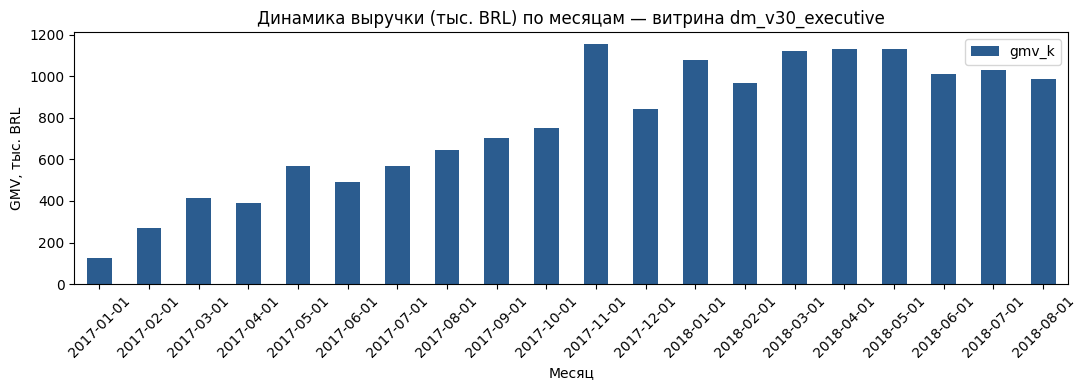

In [21]:
# ✏️ ЗАДАНИЕ 5.4
df_check = q(f"""
    SELECT month,
           COUNT(order_id) AS orders,
           ROUND(SUM(order_value) / 1e3, 1) AS gmv_k
    FROM {dm_name}
    GROUP BY month
    ORDER BY month
""")
ax = df_check.plot(x="month", y="gmv_k", kind="bar", figsize=(11, 4), color="#2b5c8f", title="Динамика выручки (тыс. BRL) по месяцам — витрина dm_v30_executive")
ax.set_ylabel("GMV, тыс. BRL")
ax.set_xlabel("Месяц")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Выгрузка витрины в CSV для DataLens
Формат под подключение DataLens «Файлы»: кодировка UTF-8, разделитель — запятая, первая строка — заголовки, даты `ГГГГ-ММ-ДД`.
Рядом сохраняется словарь полей с рекомендуемыми типами DataLens.

In [22]:
# === 6.1. Выгрузка витрины в CSV для DataLens ===
def export_for_datalens(v: int) -> Path:
    """VIEW → CSV: UTF-8, разделитель «запятая», заголовок, точка как десятичный разделитель."""
    x = VAR[v]
    df = q(f"SELECT * FROM {x['dm']}")
    path = OUT_DIR / f"{x['dm']}.csv"
    df.to_csv(path, index=False, encoding="utf-8", sep=",", float_format="%.4f")
    size_mb = path.stat().st_size / 1e6
    # ограничения подключения «Файлы»: до 200 МБ на файл и до 300 столбцов
    assert size_mb <= 200, f"Файл {size_mb:.1f} МБ больше лимита DataLens 200 МБ — укрупните гранулярность"
    assert len(df.columns) <= 300
    print(f"✔ {path.name}: {len(df):,} строк × {len(df.columns)} столбцов, {size_mb:.2f} МБ".replace(",", " "))
    return path

csv_path = export_for_datalens(VARIANT)

# Словарь полей — пригодится при настройке датасета и для README
dictionary = pd.DataFrame({"поле": q(f"SELECT * FROM {VAR[VARIANT]['dm']} LIMIT 1").columns})
sample = q(f"SELECT * FROM {VAR[VARIANT]['dm']} LIMIT 500")
dictionary["тип в pandas"] = [str(sample[c].dtype) for c in dictionary["поле"]]
dictionary["тип в DataLens"] = ["Дата" if c in ("month", "purchase_date", "first_month", "cohort_month", "last_purchase")
                                else ("Дробное число" if sample[c].dtype == float else
                                      ("Целое число" if "int" in str(sample[c].dtype) else "Строка"))
                                for c in dictionary["поле"]]
dictionary["пример"] = [sample[c].dropna().iloc[0] if sample[c].notna().any() else "" for c in dictionary["поле"]]
dictionary.to_csv(OUT_DIR / f"{VAR[VARIANT]['dm']}_dictionary.csv", index=False, encoding="utf-8")
dictionary

✔ dm_v30_executive.csv: 96 211 строк × 17 столбцов  17.25 МБ


,поле,тип в pandas,тип в DataLens,пример
0,order_id,object,Строка,76c6e866289321a7c93b82b54852dc33
1,purchase_date,object,Дата,2017-01-23
2,month,object,Дата,2017-01-01
3,year,int64,Целое число,2017
4,state,object,Строка,RS
5,state_name,object,Строка,Риу-Гранди-ду-Сул
6,region,object,Строка,Юг
7,state_lat,float64,Дробное число,-29.7147
8,state_lng,float64,Дробное число,-51.9443
9,payment_type,object,Строка,boleto


In [23]:
# === 6.2. Скачайте CSV на компьютер (в Colab откроется загрузка; локально файл уже в папке) ===
try:
    from google.colab import files          # работает только в Google Colab
    files.download(str(csv_path))
    print("Файл отправлен на скачивание:", csv_path.name)
except ImportError:
    print("Локальный запуск — файл лежит здесь:", csv_path.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Файл отправлен на скачивание: dm_v30_executive.csv


## 7. Пошаговая работа в Yandex DataLens

DataLens — облачная BI-система Яндекса (бесплатный тариф достаточен). Вход — по Яндекс ID на **[datalens.ru](https://datalens.ru)**.
Ниже — порядок действий, общий для всех вариантов; раскладку полей именно вашего варианта печатает ячейка 7.0.
Названия кнопок приведены по документации DataLens; интерфейс периодически обновляется — если подпись чуть отличается, ищите ближайшую по смыслу.

### Шаг 1. Воркбук — папка проекта
1. Откройте DataLens → в левой панели **Коллекции и воркбуки**.
2. Справа вверху **Создать → Создать воркбук**, имя: `ЛР3_<Фамилия>_вариант_<NN>` → **Создать**.
> Воркбук хранит вместе подключение, датасет, чарты и дашборд — так проще сдавать и проверять работу.

### Шаг 2. Подключение «Файлы» — загрузка CSV
1. В воркбуке **Создать → Подключение** → раздел **Файлы и сервисы** → **Файлы**.
2. **Загрузить файлы** → выберите `dm_vNN_….csv` из раздела 6. Ограничения: до 200 МБ на файл, до 10 файлов, до 300 столбцов.
3. Проверьте параметры над предпросмотром: **Кодировка** — `utf-8`, **Разделитель** — `Запятая`, **Заголовок столбцов** — `Да`.
4. Проверьте типы столбцов (значок слева от имени): поля `month`, `purchase_date`, `first_month`, `cohort_month`, `last_purchase` → **Дата**;
   суммы и доли → **Дробное число**; счётчики → **Целое число**; коды и названия → **Строка**. Ориентир — `…_dictionary.csv` из раздела 6.
5. **Создать подключение** → имя `olist_vNN` → **Создать**.

### Шаг 3. Датасет — семантический слой
1. На странице подключения справа вверху **Создать датасет** → вкладка **Поля**.
2. Для каждого показателя задайте **агрегацию** (нажмите на текущее значение): суммы, количества → **Сумма**; оценки, сроки → **Среднее**;
   идентификаторы для подсчёта → **Количество уникальных**. Поле с агрегацией становится синим — это **показатель**; зелёные поля — **измерения**.
3. Создайте вычисляемые поля вашего варианта: **Добавить поле → Вычисляемое поле** → имя и формула из карточки → **Создать**.
   > Почему не среднее от среднего: средний чек = `SUM([gmv]) / SUM([orders])`, а не среднее значение готовых средних по строкам витрины.
   > Только так показатель корректно пересчитывается при любой фильтрации на дашборде. Оператор `/` в DataLens всегда даёт дробное число.
4. **Сохранить** → имя `ds_olist_vNN` → **Создать**.

### Шаг 4. Пять обязательных чартов
1. На странице датасета **Создать чарт** (или в воркбуке **Создать → Чарт** и выбрать датасет).
2. Вверху выберите **тип визуализации** по таблице варианта: Индикатор, Линейная, Столбчатая (Линейчатая), Круговая (Кольцевая), Комбинированная.
3. Перетащите поля из списков **Измерения** и **Показатели** в секции чарта (**X**, **Y**, **Цвета**, **Сортировка**, **Подписи**, **Фильтры**) — как в карточке.
4. **Комбинированная диаграмма**: в **X** — одно поле (обычно `month`); в первом слое выберите тип «столбчатая» и показатель,
   значком справа от имени слоя добавьте второй слой «линейная» с другим показателем (до 5 слоёв).
5. **Карта** (если есть в варианте): тип **Карта**, слой **Точки (Геоточки)**, в секцию точек — вычисляемое поле `GEOPOINT([state_lat], [state_lng])`,
   в **Размер точек** — показатель.
6. Каждый чарт: **Сохранить** → понятное имя `vNN_1_Индикатор_…` → **Сохранить**.

### Шаг 5. Дашборд и интерактивность
1. В воркбуке **Создать → Дашборд**. Из нижней панели перетащите **Чарт** → **Выбрать** → нужный чарт → **Добавить**. Повторите для всех чартов.
2. Перетащите **Селектор** → датасет `ds_olist_vNN` → поле из карточки (например, `region`) → включите **Множественный выбор** → **Сохранить**.
   Добавьте все селекторы варианта. Селектор на основе того же датасета фильтрует его чарты автоматически; проверьте настройку **Связи**.
3. Добавьте **Заголовок** (название бизнес-кейса) и **Текст** (2–3 вывода). Расположите: индикаторы сверху, динамика — в центре, структура и рейтинги — ниже.
4. **Сохранить** → имя `ЛР3_вариант_NN_<бизнес-кейс>` → **Создать**.

### Шаг 6. Доступ, скриншоты, обновление данных
1. Откройте доступ к дашборду для преподавателя (или опубликуйте по публичной ссылке — данные Olist открытые) и скопируйте ссылку в `README.md`.
2. Сделайте скриншоты: дашборд целиком, датасет (вкладка **Поля**), один чарт в режиме редактирования.
3. Если витрину пришлось исправить: в подключении нажмите **Заменить** у файла → загрузите новый CSV → **Сохранить изменения** —
   датасет, чарты и дашборд обновятся без пересоздания.

In [24]:
# === 7.0. Раскладка дашборда вашего варианта (сверяйтесь при настройке DataLens) ===
x = VAR[VARIANT]
plan = [(i, t, n, s) for i, (t, n, s) in enumerate(x["charts"], 1)]
if x.get("extra"):
    plan.append(("доп.", *x["extra"]))
display(Markdown(
    f"**Файл:** `{x['dm']}.csv` → **подключение** `olist_v{VARIANT:02d}` → **датасет** `ds_olist_v{VARIANT:02d}`\n\n"
    "**Вычисляемые поля:** " + "; ".join(f"`{k}` = `{f}`" for k, f in x["calc"].items()) + "\n\n"
    "**Селекторы:** " + ", ".join(f"`{s}`" for s in x["selectors"])))
pd.DataFrame(plan, columns=["№", "тип визуализации", "название чарта", "поля по секциям"]).set_index("№")

**Файл:** `dm_v30_executive.csv` → **подключение** `olist_v30` → **датасет** `ds_olist_v30`

**Вычисляемые поля:** `GMV` = `SUM([order_value])`; `Заказов` = `COUNTD([order_id])`; `Средний чек` = `SUM([order_value]) / COUNTD([order_id])`; `Доля опозданий` = `AVG([is_late])`; `Геоточка` = `GEOPOINT([state_lat], [state_lng])`

**Селекторы:** `year`, `region`, `payment_type`

,тип визуализации,название чарта,поля по секциям
№,,,
1,Индикатор,"GMV, BRL",Показатель: «GMV» (+ отдельные индикаторы «Зак...
2,Линейная диаграмма,Выручка по месяцам,X: month; Y: «GMV»
3,Столбчатая диаграмма,Выручка по регионам,X: region; Y: «GMV»; Сортировка ↓
4,Кольцевая диаграмма,Способы оплаты,Цвета: payment_type; Показатели: «GMV»; Подпис...
5,Комбинированная диаграмма,Заказы и средний чек,X: month; Слой 1 столбцы: «Заказов»; Слой 2 ли...
доп.,Карта,Карта выручки,Точки: «Геоточка»; Размер точек: «GMV»; Цвета:...


## 8. Отчёт
Ячейка ниже собирает черновик `README.md` по вашему варианту: цель, метрики, архитектуру, SQL витрины и контрольные значения.
Допишите выводы (3 пункта с цифрами с дашборда), вставьте ссылку на дашборд и скриншоты из папки `img/`.

**Структура репозитория:**
```
lab3_<фамилия>/
├── lab3_student.ipynb                 # этот ноутбук с выполненными ячейками
├── sql/dm_vNN_<кейс>.sql              # SQL витрины (CREATE VIEW …)
├── data/dm_vNN_<кейс>_dictionary.csv  # словарь полей витрины
├── img/dashboard.png, img/dataset.png # скриншоты DataLens
└── README.md                          # отчёт
```
Сам CSV витрины и файл `olist_dwh.sqlite` в репозиторий **не кладите** (большие файлы); исходные данные воспроизводятся ноутбуком.

In [26]:
# === 8.1. Черновик отчёта README.md (заполните выводы и ссылки) ===
x = VAR[VARIANT]
ctrl_md = "\n".join(f"| {r['контрольный вопрос']} | {r['ответ']} |" for _, r in controls.iterrows())
chart_md = "\n".join(f"| {i} | {t} | {n} |" for i, (t, n, s) in enumerate(x["charts"], 1))
readme = f"""# ЛР-3. Аналитический дашборд для бизнес-кейса — вариант {VARIANT}

**Студент:** {STUDENT} · **группа:** {GROUP}
**Бизнес-кейс:** {x['title']}

## Цель работы
{x['question']}

## Исследуемые метрики
{chr(10).join('- **' + k + '** = `' + f + '`' for k, f in x['calc'].items())}

## Архитектура решения
Kaggle (Olist, 9 CSV) → Python (`urllib`, `pandas`) → SQLite: RAW → STAGING → CORE → витрина `{x['dm']}` → CSV → Yandex DataLens.

## Технологический стек
Python {sys.version.split()[0]}, pandas {pd.__version__}, SQLite {sqlite3.sqlite_version}, Google Colab / Jupyter, Yandex DataLens.

## Схема данных
Слои: `raw_*` (9 таблиц) → `stg_*` (типизация, очистка) → `core_order`, `core_item`, `dim_state` → `{x['dm']}` (VIEW).
<!-- вставьте скриншот или ER-диаграмму: img/er.png -->

## SQL витрины
```sql
CREATE VIEW {x['dm']} AS
{DM_SQL.strip()}
```

## Контрольные значения
| Вопрос | Ответ |
|---|---|
{ctrl_md}

## Дашборд DataLens
Ссылка: <!-- https://datalens.yandex/2efiwk4mhcx6l?_share_link=public-->

| № | Тип | Название |
|---|---|---|
{chart_md}

![Дашборд](img/dashboard.png)

![Датасет](img/dataset.png)

![Настройка чарта](img/chart.png)

## Выводы и бизнес-рекомендации
1. **Экстенсивный рост оборота при стабильном среднем чеке:** за январь 2017 – август 2018 гг. выручка доставленных заказов (`GMV`) достигла **15,37 млн BRL** (**96 211** заказов). Месячный оборот вырос в **7,7 раза** (со **127,5 тыс. BRL** в январе 2017 г. до плато **0,99–1,13 млн BRL** в марте–августе 2018 г., пик — **1,15 млн BRL** в ноябре 2017 г.) при стабильном среднем чеке **159,79 BRL** (коридор 146–170 BRL).
2. **Высокая географическая концентрация и логистическое неравенство:** макрорегион **Юго-Восток** (`Sudeste`) формирует **64,6% всей выручки** (**9,93 млн BRL**, `66 027` заказов), включая **37,4%** по одному штату Сан-Паулу (`SP`). В удалённых регионах сроки и опоздания вдвое выше: **20,0 дн.** и **12,8% опозданий** на Северо-Востоке (`1,82 млн BRL`, `11,8% GMV`), **22,6 дн.** и **8,6%** на Севере против **10,7 дн.** и **6,1% опозданий** на Юго-Востоке.
3. **Доминирование кредитных карт и критическое влияние опозданий на рейтинг:** **78,5% GMV** (**12,06 млн BRL**) оплачивается кредитными картами (средний чек **166,09 BRL** за счёт рассрочки), **18,0%** — через *boleto* (**144,32 BRL**). При доставке вовремя средняя оценка клиента составляет **4,29**, но при опоздании падает почти вдвое — до **2,27** (общий рейтинг — **4,16**, доля опозданий — **6,79%**).
4. **Управленческая рекомендация:** открыть партнёрский распределительный центр (3PL) и привлечь локальных продавцов в макрорегионе **Северо-Восток** (штаты `BA`, `PE`), а также скорректировать расчёт обещанных сроков доставки (`estimated_date`) для межрегиональных заказов. Снижение доли опозданий на Северо-Востоке с **12,8%** до уровня Юго-Востока (**6,1%**) позволит предотвратить около **450–500 негативных отзывов (1–2 звезды)** в год и повысить повторные продажи.
"""
(WORK_DIR / "README.md").write_text(readme, encoding="utf-8")
print("Черновик сохранён:", (WORK_DIR / "README.md").resolve())
print(readme[:1200], "…")

Черновик сохранён: /content/lab3_olist/README.md
# ЛР-3. Аналитический дашборд для бизнес-кейса — вариант 30

**Студент:** Трусов А.И. · **группа:** БД-251м
**Бизнес-кейс:** Дашборд руководителя e-commerce (эталон преподавателя)

## Цель работы
Как чувствует себя бизнес в целом: выручка, заказы, средний чек, география, способы оплаты, доставка и удовлетворённость клиентов?

## Исследуемые метрики
- **GMV** = `SUM([order_value])`
- **Заказов** = `COUNTD([order_id])`
- **Средний чек** = `SUM([order_value]) / COUNTD([order_id])`
- **Доля опозданий** = `AVG([is_late])`
- **Геоточка** = `GEOPOINT([state_lat], [state_lng])`

## Архитектура решения
Kaggle (Olist, 9 CSV) → Python (`urllib`, `pandas`) → SQLite: RAW → STAGING → CORE → витрина `dm_v30_executive` → CSV → Yandex DataLens.

## Технологический стек
Python 3.13.18, pandas 2.2.3, SQLite 3.45.1, Google Colab / Jupyter, Yandex DataLens.

## Схема данных
Слои: `raw_*` (9 таблиц) → `stg_*` (типизация, очистка) → `core_order`, `core_item`, 

In [ ]:
# === 8.2. SQL витрины — отдельным файлом для репозитория ===
(WORK_DIR / "sql").mkdir(exist_ok=True)
sql_file = WORK_DIR / "sql" / f"{VAR[VARIANT]['dm']}.sql"
sql_file.write_text(f"DROP VIEW IF EXISTS {VAR[VARIANT]['dm']};\nCREATE VIEW {VAR[VARIANT]['dm']} AS\n{DM_SQL.strip()};\n", encoding="utf-8")
print("Сохранено:", sql_file)

In [ ]:
# === 9. Итоговая самопроверка перед сдачей ===
x = VAR[VARIANT]
final = {
    "1. Хранилище построено (core_order, core_item)": all(q(f"SELECT COUNT(*) AS n FROM sqlite_master WHERE name='{t}'").n[0] == 1
                                                         for t in ("core_order", "core_item", "dim_state")),
    "2. Автотесты конвейера пройдены":                all(dq.values()),
    "3. Витрина варианта прошла автотест":            bool(check_datamart(VARIANT, verbose=False)["ok"].all()),
    "4. Контрольные значения рассчитаны":             controls["ответ"].notna().all(),
    "5. CSV для DataLens выгружен":                   (OUT_DIR / f"{x['dm']}.csv").exists(),
    "6. Черновик README.md создан":                   (WORK_DIR / "README.md").exists(),
}
for k, ok in final.items():
    print("✔" if ok else "✘", k)
print("\nДальше — DataLens (раздел 7), скриншоты и выводы в README.md, загрузка в Git.")

## 10. Повышенная сложность (для желающих, отмечается в отчёте)
1. **Конвейер как программа.** Перенесите разделы 2–6 в файл `pipeline.py` с функциями `extract()`, `load_raw()`, `transform()`, `build_mart(v)`, `export(v)`
   и запуском `python pipeline.py --variant NN`. Это прямой аналог DAG Airflow: те же задачи, та же последовательность, но без оркестратора.
2. **Инкрементальная загрузка.** Добавьте в `etl_load_log` хеш файла и пропускайте загрузку, если архив не изменился.
3. **Второй источник.** Добавьте в DataLens второй файл (например, `dim_state` или витрину соседнего варианта) и свяжите таблицы в датасете по общему полю.
4. **Прямое подключение к СУБД.** Загрузите `core_order` в управляемую PostgreSQL или ClickHouse и подключите DataLens к базе вместо CSV —
   обсудите в выводах, когда файловое подключение достаточно, а когда нужна СУБД.